<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">
<br>
<h1 style="font-family:verdana; font-size:26px"><center>~ DAC FindIT! 2026: Face Anti-Spoofing dengan DINOv2 ~</center></h1>
<h3 style="font-family:verdana; font-size:14px; color:gray"><center>Klasifikasi serangan presentasi pada sistem pengenalan wajah</center></h3>

<br>
<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

# **KantinBorju**

<p style="font-size:16px; font-family:verdana">- Izhar Alif Akbar <br>- Razi Rachman Widyadhana (Leader)<br>- Farrel Athalla Putra</p>

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

# Daftar Isi

1. [**Pendahuluan**](#1)
2. [**Inisialisasi**](#2)
3. [**Analisis Data Eksploratif**](#3)
4. [**Prapemrosesan dan Augmentasi**](#4)
5. [**Pembagian Data dan DataLoader**](#5)
6. [**Pemodelan**](#6)
7. [**Inferensi dan Submisi**](#7)
8. [**Pasca-Analisis**](#8)
9. [**Daftar Pustaka**](#9)

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

# Pendahuluan <a name="1"></a>

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

## Kompetisi

Sistem pengenalan wajah (*face recognition*) yang digunakan pada berbagai platform digital rentan terhadap serangan presentasi (*presentation attack*), yaitu upaya menembus sistem otentikasi menggunakan media pengganti wajah asli. Serangan ini mencakup penggunaan foto cetak, layar digital, masker silikon, hingga manekin. Pada kompetisi **DAC FindIT! 2026**, peserta ditantang membangun model AI/ML yang mampu membedakan wajah asli dari berbagai metode serangan tersebut.

- **Tugas**: klasifikasi gambar ke dalam 6 kelas
- **Kelas target**: `realperson`, `fake_printed`, `fake_mannequin`, `fake_mask`, `fake_screen`, `fake_unknown`
- **Platform**: Kaggle Notebook, GPU T4 x2

---

## Dataset

*Dataset* terdiri dari dua kategori besar: foto wajah asli (*realperson*) dan foto serangan presentasi yang dibagi menjadi lima jenis. Serangan jenis *printed* menggunakan foto cetak, *screen* mengandalkan layar digital untuk memutar ulang gambar, *mask* menggunakan masker 3D berbahan silikon atau resin, *mannequin* menggunakan kepala manekin, sementara *unknown* mencakup metode serangan yang belum terklasifikasi. Setiap gambar dalam *test set* perlu diklasifikasikan ke salah satu dari keenam kelas ini.

---

## Pendekatan: DINOv2-Large *Partial Fine-Tuning* + *Stratified K-Fold*

DINOv2-Large adalah *vision foundation model* hasil pelatihan *self-supervised* Meta AI menggunakan arsitektur ViT-L/14. Model ini menghasilkan representasi fitur yang kaya dan terbukti unggul pada berbagai tugas visi (Oquab dkk., 2024).

Pendekatan ini menggunakan DINOv2-Large dengan *partial fine-tuning*: enam blok *encoder* terakhir (lapisan 18–23) dibuka untuk dilatih, sementara lapisan sebelumnya tetap dibekukan. *Head* klasifikasi dua lapisan ditambahkan di atas token CLS *backbone*. Optimizer AdamW dengan dua *learning rate* berbeda digunakan: LR lebih kecil untuk lapisan *backbone* yang dibuka, dan LR lebih besar untuk *head*.

```
DINOv2 ViT-L/14 (6 encoder layers terakhir di-finetune)
    |
    +-- CLS token [1024-dim]  -- identitas global wajah
         |
    LayerNorm(1024)
         |
    Linear(1024, 512) -> GELU -> Dropout(0.3)
         |
    Linear(512, 6) -> prediksi kelas
```

Pembagian data menggunakan *Stratified K-Fold* (5 *fold*) untuk memastikan distribusi kelas yang merata antara *training* dan *validation set*. Fold 0 digunakan sebagai *validation set*. *Class weights* dihitung berdasarkan frekuensi invers untuk menangani ketidakseimbangan kelas.

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

# Inisialisasi <a name="2"></a>

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

## Environment

In [ ]:
!nvidia-smi

Fri Apr 10 15:51:12 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.105.08             Driver Version: 580.105.08     CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   47C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

> Catatan untuk juri dan panitia: untuk mereproduksi submisi tanpa menjalankan *training* dari awal, cukup tetapkan `Settings.RUN_NAME = 'INFERENCE'`, kemudian jalankan *Run All*.

In [ ]:
import os, platform, sys
print('Python :', sys.version)
print('OS     :', platform.system(), platform.release())
print('CWD    :', os.getcwd())

Python : 3.12.12 (main, Oct 10 2025, 08:52:57) [GCC 11.4.0]
OS     : Linux 6.6.113+
CWD    : /kaggle/working


---

## Instalasi

Baris berikut memasang seluruh pustaka yang diperlukan pada *notebook* ini. Pustaka *transformers* perlu dipasang dari versi terkini agar kompatibel dengan model DINOv2. *Albumentations* digunakan sebagai *pipeline* augmentasi data karena kemudahannya dikombinasikan dengan format NumPy.

In [ ]:
%pip install -q --upgrade transformers
%pip install -q timm huggingface_hub albumentations opencv-python-headless python-dotenv gdown networkx
%pip install -q insightface onnxruntime-gpu

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.2/10.2 MB 69.4 MB/s eta 0:00:00:00:01:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 642.6/642.6 kB 43.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.2/4.2 MB 101.5 MB/s eta 0:00:0000:01
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


---

## Pustaka

Seluruh impor dikelompokkan dalam satu sel agar mudah ditelusuri dan diperbarui. PyTorch digunakan sebagai *framework* utama, *transformers* menyediakan akses ke model DINOv2, sementara *albumentations* menangani *pipeline* augmentasi data dengan antarmuka NumPy.

In [ ]:
import csv
import hashlib
import math
import os
import random
import shutil
import sys
import zipfile
import warnings
from collections import Counter, defaultdict
from pathlib import Path

import networkx as nx
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
from PIL import Image, ImageOps
from tqdm import tqdm
import cv2
from insightface.app import FaceAnalysis

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import f1_score, classification_report, confusion_matrix
import albumentations as A
from albumentations.pytorch import ToTensorV2
import gdown
from huggingface_hub import login
from transformers import AutoModel

warnings.filterwarnings('ignore')
print('PyTorch   :', torch.__version__)
print('CUDA      :', torch.version.cuda)
print('Device    :', 'cuda' if torch.cuda.is_available() else 'cpu')


PyTorch   : 2.10.0+cu128
CUDA      : 12.8
Device    : cuda


---

## Seed

Pengaturan *seed* dilakukan pada semua sumber keacakan agar hasil pelatihan dapat direproduksi. Meskipun demikian, operasi berbasis GPU tetap dapat menghasilkan sedikit galat numerik antar eksekusi akibat perbedaan penjadwalan *hardware*.

In [ ]:
def seed_everything(seed: int = 42):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

seed_everything(42)

---

## Settings

Kelas `Settings` memusatkan seluruh konfigurasi eksperimen: *hyperparameter* pelatihan, jalur data, dan konfigurasi model. DINOv2-Large menggunakan resolusi input 336×336 px (sesuai ViT-L/14 *patch size* 14). Ubah `RUN_NAME` menjadi `'INFERENCE'` untuk melewati *training* dan langsung memuat *checkpoint* terbaik.

In [ ]:
class Settings:
    SEED        = 42

    # Mode (ganti 'INFERENCE' untuk skip training)
    RUN_NAME    = 'dinov2-v0-baseline'

    # Classes (alphabetical)
    CLASS_NAMES = [
        'fake_mannequin', 'fake_mask', 'fake_printed',
        'fake_screen', 'fake_unknown', 'realperson',
    ]
    N_CLASSES   = len(CLASS_NAMES)
    CLASS2IDX   = {c: i for i, c in enumerate(CLASS_NAMES)}
    IDX2CLASS   = {i: c for i, c in enumerate(CLASS_NAMES)}

    # Model
    MODEL_NAME  = 'facebook/dinov2-large'
    IMG_SIZE    = 336

    # Training
    EPOCHS              = 15
    BATCH_SIZE          = 8
    ACCUM_STEPS         = 4       # effective batch = BATCH_SIZE * ACCUM_STEPS = 32
    LR                  = 2e-5   # backbone (layer 18-23)
    HEAD_LR             = 1e-4   # classification head
    WEIGHT_DECAY        = 1e-2
    DROPOUT             = 0.3
    EARLY_STOP_PATIENCE = 10
    USE_AMP             = True

    # K-Fold
    NUM_FOLDS  = 5
    TRAIN_FOLD = 0    # fold yang dipakai sebagai validation

    # Normalisation (ImageNet stats)
    IMAGENET_MEAN = (0.485, 0.456, 0.406)
    IMAGENET_STD  = (0.229, 0.224, 0.225)

    # DataLoader
    NUM_WORKERS = 0

    # EDA visualisation
    EDA_SAMPLE_COLS     = 5
    EDA_PALETTE_NAME    = 'flare'
    CLASS_DISPLAY_NAMES = [name.replace('fake_', '') for name in CLASS_NAMES]

    # Paths
    _ON_KAGGLE  = Path('/kaggle/input').exists()
    _LOCAL_DATA = Path('../../dataset')
    _CLOUD_DATA = Path('dataset')
    _DATA_ROOT  = (
        Path('/kaggle/input') if _ON_KAGGLE else
        _LOCAL_DATA           if _LOCAL_DATA.exists() else
        _CLOUD_DATA
    )
    TRAIN_DIR = (
        Path('/kaggle/input/datasets/zirach/dac-findit-2026/train') if _ON_KAGGLE else
        _DATA_ROOT / 'train'
    )
    TEST_DIR  = (
        Path('/kaggle/input/datasets/zirach/dac-findit-2026/test') if _ON_KAGGLE else
        _DATA_ROOT / 'test'
    )
    _BASE_OUT = (
        Path('/kaggle/working') if _ON_KAGGLE else
        Path('../../output')    if _LOCAL_DATA.exists() else
        Path('output')
    )
    OUTPUT_DIR      = _BASE_OUT / 'dinov2-large' / RUN_NAME
    CHECKPOINT_PATH = OUTPUT_DIR / f'{RUN_NAME}_best.pth'
    SUBMISSION_CSV  = OUTPUT_DIR / f'submission_{RUN_NAME}.csv'


CFG = Settings()
CFG.OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

EDA_PALETTE = sns.color_palette(CFG.EDA_PALETTE_NAME, CFG.N_CLASSES)

seed_everything(CFG.SEED)
print(f'Run       : {CFG.RUN_NAME}')
print(f'TRAIN_DIR : {CFG.TRAIN_DIR}  exists={CFG.TRAIN_DIR.exists()}')
print(f'TEST_DIR  : {CFG.TEST_DIR}   exists={CFG.TEST_DIR.exists()}')
print(f'OUTPUT_DIR: {CFG.OUTPUT_DIR}')


Run       : dinov2_large_v1_stratifiedkfold
TRAIN_DIR : /kaggle/input/datasets/frallex/dacdac/train_clean  exists=True
TEST_DIR  : /kaggle/input/datasets/frallex/dacccc/test   exists=True
OUTPUT_DIR: /kaggle/working/dinov2-large/dinov2_large_v1_stratifiedkfold


---

## Autentikasi Hugging Face

Model DINOv2 diunduh dari Hugging Face Hub dan memerlukan token autentikasi. Prioritas pencarian token:

`HF_TOKEN` dapat diperoleh melalui pranala berikut, pastikan telah login:

https://huggingface.co/settings/tokens

Berikut tahapan pada cell:

1. **Kaggle Secrets** (`HF_TOKEN`) -- saat berjalan di Kaggle
2. **File `.env`** di direktori kerja -- untuk pengembangan lokal
3. **Variabel lingkungan** `HF_TOKEN` -- fallback umum

Untuk pengembangan lokal, isi berkas `.env` dengan `HF_TOKEN=hf_...`.

In [ ]:
if Path('/kaggle/working').exists():
    from kaggle_secrets import UserSecretsClient
    _hf_token = UserSecretsClient().get_secret('HF_TOKEN')
    print('HF token: Kaggle Secrets')
elif Path('.env').exists():
    from dotenv import load_dotenv
    load_dotenv()
    _hf_token = os.getenv('HF_TOKEN', '')
    print('HF token: .env')
else:
    _hf_token = os.getenv('HF_TOKEN', '')
    print('HF token: variabel lingkungan')

if _hf_token:
    login(token=_hf_token)
    print('Login Hugging Face berhasil.')
else:
    print('[WARN] HF_TOKEN tidak ditemukan. Unduhan model mungkin gagal.')

HF token: Kaggle Secrets
Login Hugging Face berhasil.


---

## Unduh Data

Sel berikut mengunduh *dataset* dari Google Drive apabila *dataset* belum tersedia di jalur lokal maupun Kaggle. Proses ini dilewati secara otomatis jika direktori data sudah ada.

In [ ]:
if not CFG.TRAIN_DIR.exists():
    DATA_URL = 'https://drive.google.com/uc?id=1HpQdRgQoRSp-4FRmZIKnYInwbsGI0lHP'
    ZIP_PATH = CFG._BASE_OUT / 'dataset.zip'
    CFG._BASE_OUT.mkdir(parents=True, exist_ok=True)
    gdown.download(DATA_URL, str(ZIP_PATH), quiet=False)
    print(f'Berhasil diunduh ke {ZIP_PATH}')
else:
    ZIP_PATH = None
    print('Dataset sudah tersedia, pengunduhan dilewati.')


Dataset sudah tersedia, pengunduhan dilewati.


---

## Ekstraksi ZIP

Jika dataset diunduh sebagai arsip ZIP, sel ini mengekstraknya ke direktori data. Proses ini dilewati apabila direktori train sudah ada.

In [ ]:
if ZIP_PATH is not None and ZIP_PATH.exists() and not CFG.TRAIN_DIR.exists():
    with zipfile.ZipFile(ZIP_PATH, 'r') as zf:
        zf.extractall(CFG._DATA_ROOT)
    print(f'Diekstrak ke {CFG._DATA_ROOT}')
else:
    print('Ekstraksi dilewati.')

Ekstraksi dilewati.


---

## Persiapan Direktori

Sel berikut memindai direktori *training* untuk membangun daftar pasangan (path, label). Setiap gambar diindeks beserta label kelasnya untuk keperluan EDA dan pelatihan model.

In [ ]:
IMAGE_SUFFIXES = {'.jpg', '.jpeg', '.png', '.bmp', '.webp'}

def list_images(root_dir):
    root_dir = Path(root_dir)
    if not root_dir.exists():
        return []
    return [p for p in root_dir.iterdir()
            if p.is_file() and p.suffix.lower() in IMAGE_SUFFIXES]

def build_pairs(root_dir, class_names):
    pairs = []
    for idx, cls in enumerate(class_names):
        cls_dir = Path(root_dir) / cls
        if not cls_dir.exists():
            print(f'  [WARN] tidak ditemukan: {cls_dir}')
            continue
        for p in list_images(cls_dir):
            pairs.append((p, idx))
    return pairs

# Tidak ada EXIF correction -- sama persis dengan notebook asli
def load_rgb_image(path):
    return Image.open(path).convert('RGB')

raw_train_pairs = build_pairs(CFG.TRAIN_DIR, CFG.CLASS_NAMES)
test_images     = list_images(CFG.TEST_DIR)

print(f'Pasangan train : {len(raw_train_pairs)}')
print(f'Gambar test    : {len(test_images)}')
for idx, cls in enumerate(CFG.CLASS_NAMES):
    n = sum(1 for _, i in raw_train_pairs if i == idx)
    print(f'  {cls:20s}: {n}')


Pasangan train : 1474
Gambar test    : 404
  fake_mannequin      : 195
  fake_mask           : 261
  fake_printed        : 107
  fake_screen         : 191
  fake_unknown        : 320
  realperson          : 400


<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

# Analisis Data Eksploratif <a name="3"></a>

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

Bagian EDA menggunakan **raw train/test** agar pola distribusi, variasi resolusi, dan contoh visual masih merefleksikan kondisi mentah dataset sebelum pembersihan.

---

## Distribusi Kelas

Ketidakseimbangan kelas (*class imbalance*) yang signifikan akan memengaruhi pemilihan fungsi *loss* dan strategi *sampling* pada tahap pelatihan. Visualisasi berikut menunjukkan jumlah sampel di setiap kelas pada **raw train set**.

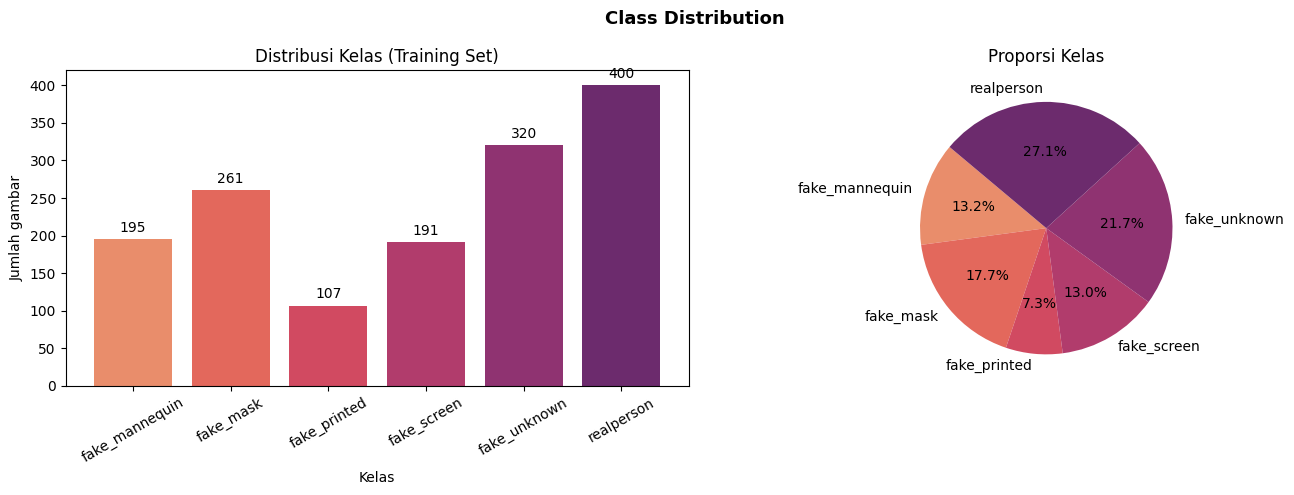

Total raw training : 1474
Rasio maks/min : 3.74x


In [ ]:
class_counts = Counter(i for _, i in raw_train_pairs)
labels = [CFG.CLASS_NAMES[i] for i in sorted(class_counts)]
values = [class_counts[i] for i in sorted(class_counts)]
total  = sum(values)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

bars = ax1.bar(labels, values, color=EDA_PALETTE)
ax1.bar_label(bars, padding=3)
ax1.set_xlabel('Kelas')
ax1.set_ylabel('Jumlah gambar')
ax1.set_title('Distribusi Kelas (Training Set)')
ax1.tick_params(axis='x', rotation=30)

ax2.pie(values, labels=labels, colors=EDA_PALETTE, autopct='%1.1f%%', startangle=140)
ax2.set_title('Proporsi Kelas')

fig.suptitle('Class Distribution', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(CFG.OUTPUT_DIR / '01_class_distribution.png', dpi=120, bbox_inches='tight')
plt.show()

print(f'Total raw training : {total}')
print(f'Rasio maks/min : {max(values)/min(values):.2f}x')

> ### Insights
> Distribusi kelas menentukan apakah diperlukan *class weighting* atau *oversampling* > pada pelatihan. Rasio ketidakseimbangan di atas 3x umumnya cukup untuk memengaruhi > metrik *macro F1* secara signifikan. Apabila rasio tersebut terdeteksi, > `class_weight='balanced'` atau `WeightedRandomSampler` perlu dipertimbangkan.

---

## Sampel Gambar per Kelas

Visualisasi sampel dari setiap kelas membantu memahami perbedaan visual antar jenis serangan. Perbedaan tekstur permukaan, pencahayaan, dan artefak kamera merupakan petunjuk utama yang perlu dibedakan oleh *patch token* DINOv2.

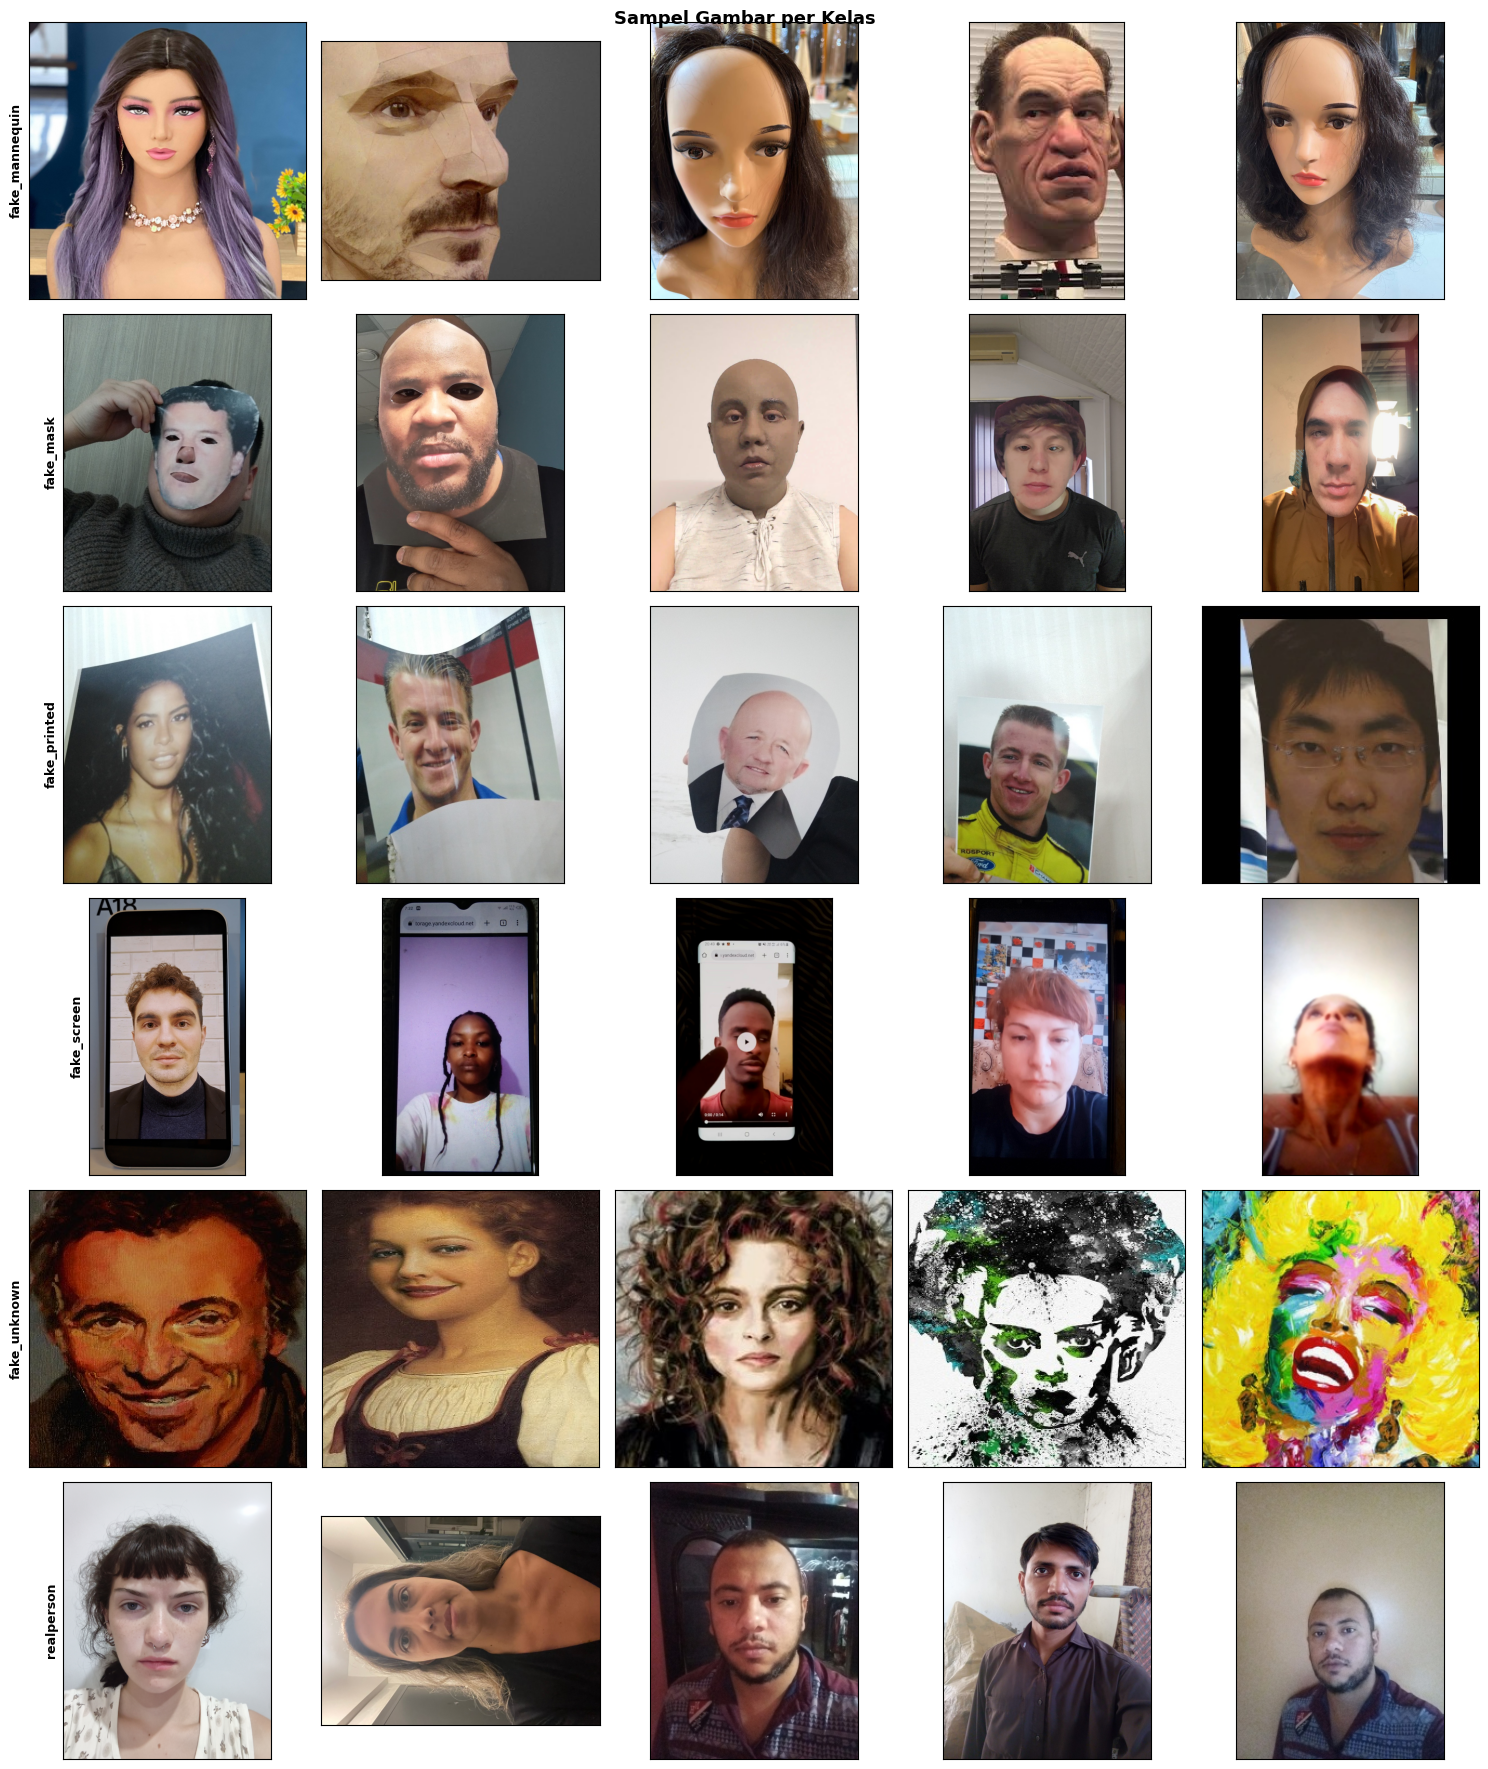

In [ ]:
fig, axes = plt.subplots(CFG.N_CLASSES, CFG.EDA_SAMPLE_COLS,
                         figsize=(CFG.EDA_SAMPLE_COLS * 3, CFG.N_CLASSES * 3))

for row, cls_name in enumerate(CFG.CLASS_NAMES):
    cls_pairs = [(p, i) for p, i in raw_train_pairs if i == row]
    samples   = random.sample(cls_pairs, min(CFG.EDA_SAMPLE_COLS, len(cls_pairs)))
    for col in range(CFG.EDA_SAMPLE_COLS):
        ax = axes[row, col]
        if col < len(samples):
            img_path, label_idx = samples[col]
            img = load_rgb_image(img_path)
            ax.imshow(img)
            if col == 0:
                ax.set_ylabel(cls_name, fontsize=9, fontweight='bold')
        else:
            ax.axis('off')
        ax.set_xticks([])
        ax.set_yticks([])

fig.suptitle('Sampel Gambar per Kelas', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(CFG.OUTPUT_DIR / '02_class_samples.png', dpi=100, bbox_inches='tight')
plt.show()

> ### Insights
> Perhatikan apakah serangan *fake_mask* secara visual menyerupai *realperson*, > karena keduanya merupakan pasangan tersulit berdasarkan hipotesis dalam `docs/MODEL_ZOO.md`. > Perbedaan tekstur permukaan (kulit organik vs. silikon) adalah fitur diskriminatif > yang paling menentukan performa model pada pasangan kelas ini.

---

## Distribusi Resolusi Gambar

Variasi resolusi dan *aspect ratio* antar gambar berpengaruh pada strategi *resizing* dalam *pipeline* pemrosesan. Gambar dengan resolusi terlalu rendah berisiko kehilangan detail tekstur yang kritis untuk membedakan kelas serangan.

Membaca dimensi gambar: 100%|██████████| 500/500 [00:12<00:00, 39.91it/s]


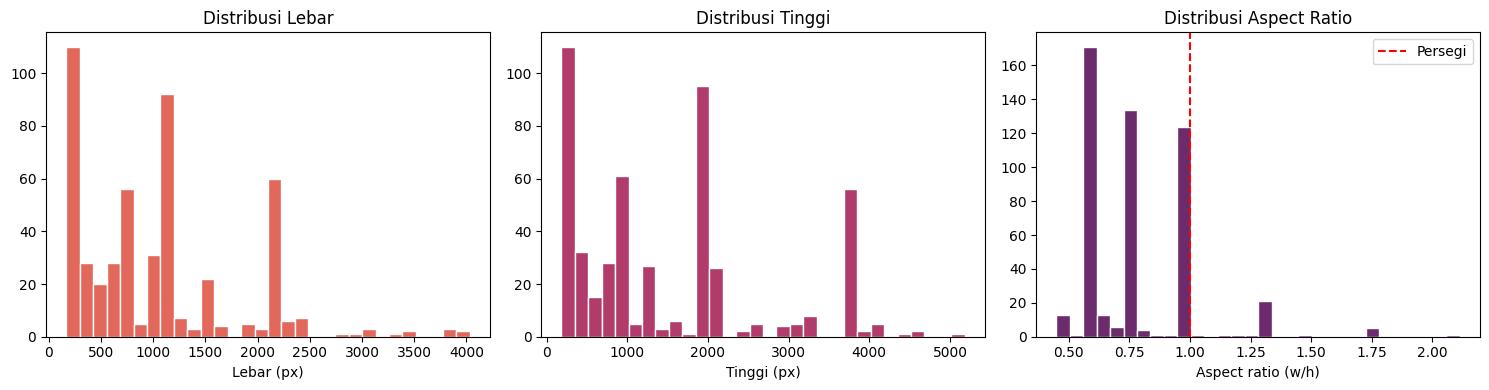

Lebar  -- min: 168 | mean: 1029 | max: 4032
Tinggi -- min: 183 | mean: 1518 | max: 5184


In [ ]:
widths, heights = [], []
sample_for_res = random.sample(raw_train_pairs, min(500, len(raw_train_pairs))) if raw_train_pairs else []

for p, label_idx in tqdm(sample_for_res, desc='Membaca dimensi gambar'):
    img = load_rgb_image(p)
    w, h = img.size
    widths.append(w)
    heights.append(h)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].hist(widths,  bins=30, color=EDA_PALETTE[1], edgecolor='white')
axes[0].set_xlabel('Lebar (px)')
axes[0].set_title('Distribusi Lebar')

axes[1].hist(heights, bins=30, color=EDA_PALETTE[3], edgecolor='white')
axes[1].set_xlabel('Tinggi (px)')
axes[1].set_title('Distribusi Tinggi')

ar = [w/h for w, h in zip(widths, heights)]
axes[2].hist(ar, bins=30, color=EDA_PALETTE[5], edgecolor='white')
axes[2].axvline(1.0, color='red', linestyle='--', label='Persegi')
axes[2].set_xlabel('Aspect ratio (w/h)')
axes[2].set_title('Distribusi Aspect Ratio')
axes[2].legend()

plt.tight_layout()
plt.savefig(CFG.OUTPUT_DIR / '03_resolution.png', dpi=120, bbox_inches='tight')
plt.show()

print(f'Lebar  -- min: {min(widths)} | mean: {np.mean(widths):.0f} | max: {max(widths)}')
print(f'Tinggi -- min: {min(heights)} | mean: {np.mean(heights):.0f} | max: {max(heights)}')

> ### Insights
> Jika mayoritas gambar sudah mendekati persegi (*aspect ratio* mendekati 1.0), > strategi `Resize` langsung ke `IMG_SIZE` lebih aman daripada `RandomResizedCrop` agresif. > Gambar dengan resolusi di bawah 112x112 perlu diperiksa secara manual karena > tekstur anti-*spoofing* kemungkinan tidak terpreservasi dengan baik.

---

## Kluster Subjek (InsightFace)

InsightFace `buffalo_l` menghasilkan *embedding* wajah 512-dim per gambar. Graf dibangun di mana setiap *node* adalah gambar dan setiap *edge* menghubungkan dua gambar dengan jarak kosinus di bawah *threshold*. Bobot *edge* diisi dengan **kemiripan kosinus** (bukan jarak) sehingga `spring_layout` menarik *node* yang mirip lebih dekat satu sama lain, mencerminkan kedekatan semantik wajah yang sesungguhnya. Visualisasi ini murni untuk EDA; tidak ada pemisahan subjek yang dilakukan.

In [ ]:
# Bangun DataFrame dari direktori train
records = []
CLASSES     = ['fake_mannequin', 'fake_mask', 'fake_printed', 'fake_screen', 'fake_unknown', 'realperson']
for cls in CLASSES:
    for img_path in (CFG.TRAIN_DIR / cls).glob('*'):
        if img_path.suffix.lower() in {'.jpg', '.jpeg', '.png'}:
            records.append({'path': str(img_path), 'class': cls,
                            'label': CFG.CLASS2IDX[cls]})
df_all = pd.DataFrame(records)
print(df_all['class'].value_counts().sort_index())
print(f'\nTotal: {len(df_all)} gambar')

class
fake_mannequin    195
fake_mask         261
fake_printed      107
fake_screen       191
fake_unknown      320
realperson        400
Name: count, dtype: int64

Total: 1474 gambar


In [ ]:
# Inisialisasi InsightFace
fa = FaceAnalysis(name='buffalo_l', providers=['CUDAExecutionProvider', 'CPUExecutionProvider'])
fa.prepare(ctx_id=0, det_size=(320, 320))

def get_embedding(img_path: str):
    """Return L2-normalised 512-dim embedding, or None if no face detected."""
    bgr = cv2.imread(img_path)
    if bgr is None:
        return None
    faces = fa.get(bgr)
    if not faces:
        return None
    emb = faces[0].normed_embedding  # already L2-normalised
    return emb

# Gunakan seluruh train set untuk clustering
cluster_records = [
    {'path': row['path'], 'class': row['class']}
    for _, row in df_all.iterrows()
]

print(f'Mengekstrak embedding untuk {len(cluster_records)} gambar...')
emb_results = []
for rec in tqdm(cluster_records, desc='InsightFace embeddings'):
    emb = get_embedding(rec['path'])
    if emb is not None:
        emb_results.append({'path': rec['path'], 'class': rec['class'], 'emb': emb})

print(f'Wajah terdeteksi: {len(emb_results)} / {len(cluster_records)}')

Applied providers: ['CUDAExecutionProvider', 'CPUExecutionProvider'], with options: {'CPUExecutionProvider': {}, 'CUDAExecutionProvider': {'sdpa_kernel': '0', 'use_tf32': '1', 'fuse_conv_bias': '0', 'prefer_nhwc': '0', 'tunable_op_max_tuning_duration_ms': '0', 'enable_skip_layer_norm_strict_mode': '0', 'tunable_op_tuning_enable': '0', 'tunable_op_enable': '0', 'use_ep_level_unified_stream': '0', 'device_id': '0', 'has_user_compute_stream': '0', 'gpu_external_empty_cache': '0', 'cudnn_conv_algo_search': 'EXHAUSTIVE', 'cudnn_conv1d_pad_to_nc1d': '0', 'gpu_mem_limit': '18446744073709551615', 'gpu_external_alloc': '0', 'gpu_external_free': '0', 'arena_extend_strategy': 'kNextPowerOfTwo', 'do_copy_in_default_stream': '1', 'enable_cuda_graph': '0', 'user_compute_stream': '0', 'cudnn_conv_use_max_workspace': '1'}}
find model: /root/.insightface/models/buffalo_l/1k3d68.onnx landmark_3d_68 ['None', 3, 192, 192] 0.0 1.0
Applied providers: ['CUDAExecutionProvider', 'CPUExecutionProvider'], with o

InsightFace embeddings: 100%|██████████| 1474/1474 [01:03<00:00, 23.24it/s]

Wajah terdeteksi: 1425 / 1474


In [ ]:
# Bangun graf dengan bobot = cosine similarity (bukan distance)
# spring_layout menarik node berbobot tinggi (sangat mirip) lebih dekat
EDA_PALETTE        = sns.color_palette('flare', 6)
CLASS_COLORS = {
    cls: EDA_PALETTE[i] for i, cls in enumerate(CLASSES)
}

EDA_CLUSTER_THRESH = 0.50 # cosine distance threshold for drawing edges
nodes   = [r['path'] for r in emb_results]
classes = [r['class'] for r in emb_results]
embs    = np.stack([r['emb'] for r in emb_results])  # [N, 512]

# Cosine similarity matrix (embeddings are already L2-normalised)
sim_matrix = embs @ embs.T  # values in [-1, 1]
# Cosine distance = 1 - similarity
dist_matrix = 1.0 - sim_matrix

G = nx.Graph()
for i, node in enumerate(nodes):
    G.add_node(node, cls=classes[i])

n = len(nodes)
for i in range(n):
    for j in range(i + 1, n):
        dist = dist_matrix[i, j]
        if dist < EDA_CLUSTER_THRESH:
            # weight = similarity so spring_layout pulls similar nodes together
            G.add_edge(nodes[i], nodes[j], weight=float(sim_matrix[i, j]))

print(f'Nodes: {G.number_of_nodes()} | Edges: {G.number_of_edges()}')
components = list(nx.connected_components(G))
print(f'Connected components: {len(components)}')
print(f'Largest component size: {max(len(c) for c in components)}')

Nodes: 1425 | Edges: 1893
Connected components: 810
Largest component size: 19


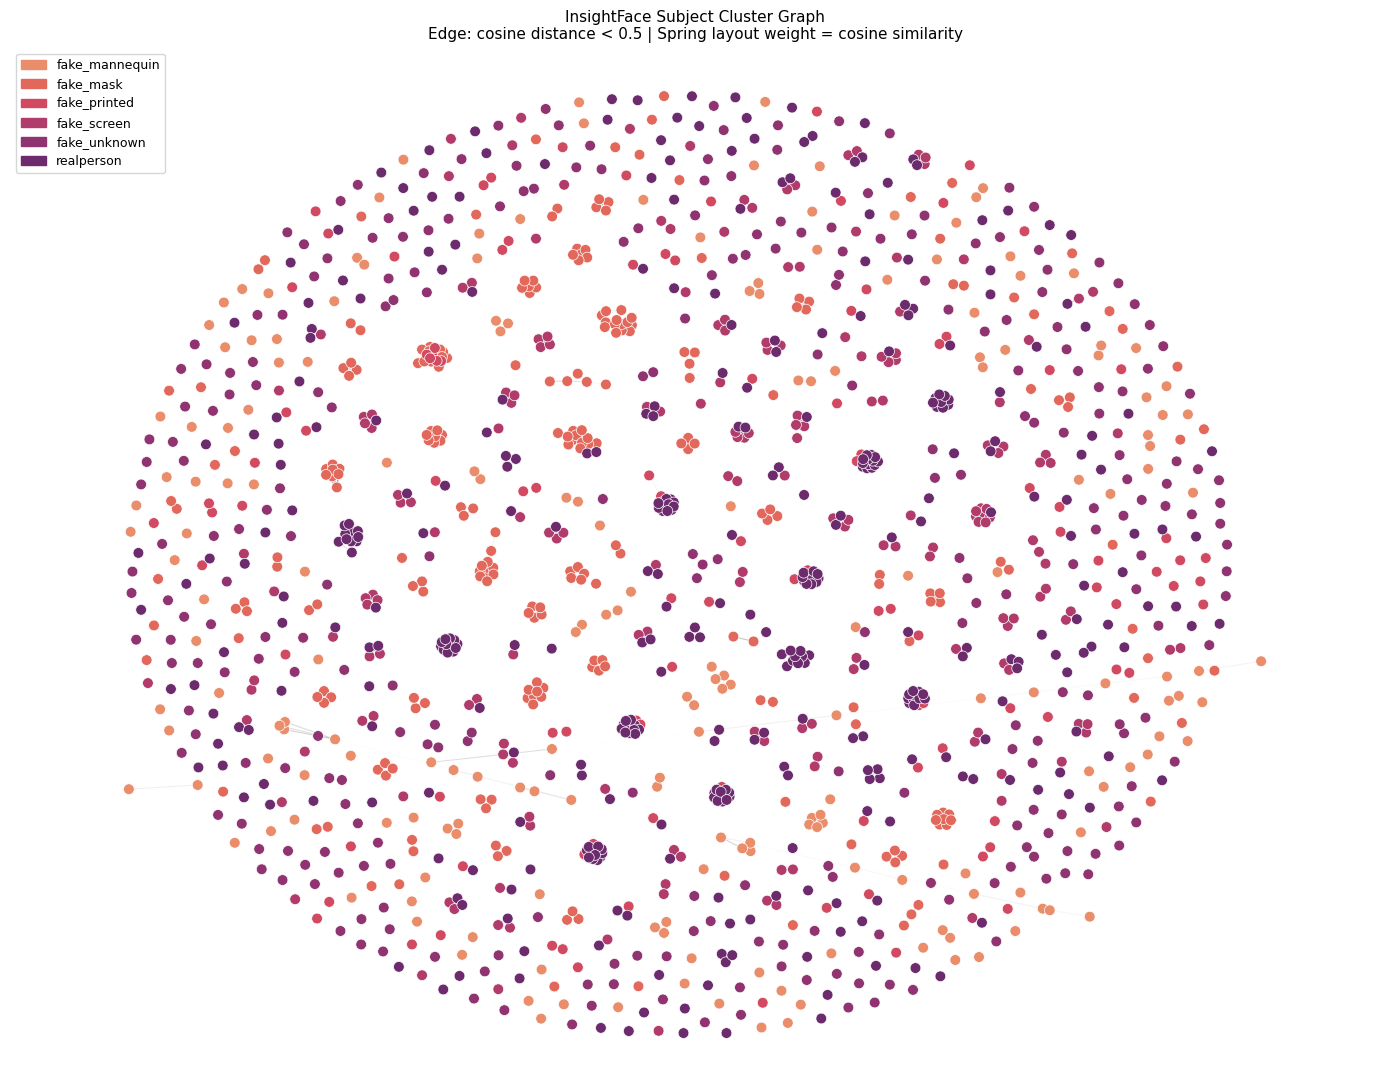

In [ ]:
# Visualisasi spring layout -- posisi mencerminkan kedekatan kosinus nyata
fig, ax = plt.subplots(figsize=(14, 11))

# spring_layout with weight: edges with higher cosine similarity
# exert stronger attraction, pulling similar-face nodes closer
pos = nx.spring_layout(G, weight='weight', seed=CFG.SEED, k=0.3, iterations=80)

node_colors = [CLASS_COLORS[G.nodes[n]['cls']] for n in G.nodes()]
edge_weights = [G[u][v]['weight'] for u, v in G.edges()]

nx.draw_networkx_edges(G, pos, ax=ax,
                       edge_color=edge_weights, edge_cmap=plt.cm.Greys,
                       width=0.8, alpha=0.5)
nx.draw_networkx_nodes(G, pos, ax=ax,
                       node_color=node_colors, node_size=60,
                       edgecolors='white', linewidths=0.5)

legend_patches = [
    mpatches.Patch(color=CLASS_COLORS[cls], label=cls)
    for cls in CLASSES
]
ax.legend(handles=legend_patches, loc='upper left', fontsize=9)
ax.set_title(
    f'InsightFace Subject Cluster Graph\n'
    f'Edge: cosine distance < {EDA_CLUSTER_THRESH} | '
    f'Spring layout weight = cosine similarity',
    fontsize=11
)
ax.axis('off')
plt.tight_layout()
plt.show()

### Insights

> *Node* yang berdekatan dalam *spring layout* adalah gambar dengan **kemiripan wajah tinggi** > dalam ruang *embedding* InsightFace. Kluster padat mengindikasikan beberapa gambar > berasal dari subjek yang sama sehingga bila masuk ke *fold* train dan val sekaligus > dapat menyebabkan *subject leakage*, yaitu model menghafalkan identitas alih-alih pola *spoofing*. > *Node* terisolasi (*singleton*) adalah gambar yang tidak memiliki kembaran wajah di *dataset* > sehingga lebih aman dimasukkan ke *validation set*. > Pada V1, *split* tetap menggunakan Stratified K-Fold standar; > pendekatan *subject-disjoint split* dapat dieksplorasi pada versi berikutnya.

---

## Pengecekan Duplikat

Bagian ini menghitung ulang **exact duplicate** berbasis SHA256 pada **raw train/test**. Tujuannya adalah memperlihatkan distribusi grup duplikat, overlap train-test, dan graf grup terbesar sebelum proses deduplikasi maupun relabel manual dijalankan.

In [ ]:
SHA256_COLORS = {
    'realperson': '#2e86de',
    'fake_printed': '#e67e22',
    'fake_mannequin': '#8e44ad',
    'fake_mask': '#16a085',
    'fake_screen': '#c0392b',
    'fake_unknown': '#7f8c8d',
    'test': '#f1c40f',
}

def sha256_file(path, chunk_size=1024 * 1024):
    hasher = hashlib.sha256()
    with open(path, 'rb') as f:
        while True:
            chunk = f.read(chunk_size)
            if not chunk:
                break
            hasher.update(chunk)
    return hasher.hexdigest()

sha_train_records = [
    {'filename': p.name, 'label': CFG.CLASS_NAMES[i], 'path': p, 'source': 'train'}
    for p, i in raw_train_pairs
]
sha_test_records = [
    {'filename': p.name, 'label': '', 'path': p, 'source': 'test'}
    for p in test_images
]
sha_records = sha_train_records + sha_test_records
df_sha = pd.DataFrame([
    {'filename': rec['filename'], 'label': rec['label'], 'source': rec['source'],
     'sha256': sha256_file(rec['path'])}
    for rec in tqdm(sha_records, desc='SHA256 raw files')
])
df_sha['node'] = df_sha['source'] + '::' + df_sha['filename']
df_sha['group_size'] = df_sha.groupby('sha256')['filename'].transform('size')
df_sha_dups = df_sha[df_sha['group_size'] > 1].copy()
df_sha_groups = (
    df_sha.groupby('sha256')
    .agg(
        size=('filename', 'size'),
        n_train=('source', lambda s: int((s == 'train').sum())),
        n_test=('source', lambda s: int((s == 'test').sum())),
        train_labels=('label', lambda s: '|'.join(sorted({x for x in s if x}))),
        members=('node', lambda s: '|'.join(sorted(s))),
    )
    .reset_index()
)
df_sha_groups = df_sha_groups[df_sha_groups['size'] > 1].copy()
df_sha_groups['has_train_test_overlap'] = ((df_sha_groups['n_train'] > 0) & (df_sha_groups['n_test'] > 0)).astype(int)
df_sha_groups['n_train_labels'] = df_sha_groups['train_labels'].map(lambda x: 0 if not x else len(x.split('|')))
df_sha_groups['is_mixed_train_label'] = (df_sha_groups['n_train_labels'] > 1).astype(int)
print(f'Total raw train images         : {len(sha_train_records)}')
print(f'Total raw test images          : {len(sha_test_records)}')
print(f'Exact duplicate groups         : {len(df_sha_groups)}')
print(f'Images in duplicate groups     : {len(df_sha_dups)}')
print(f"Train-test overlap groups      : {int(df_sha_groups['has_train_test_overlap'].sum()) if not df_sha_groups.empty else 0}")
display(df_sha_groups.sort_values(['size', 'has_train_test_overlap'], ascending=[False, False]).head(10))

SHA256 raw files: 100%|██████████| 1878/1878 [00:12<00:00, 145.08it/s]


Total raw train images         : 1474
Total raw test images          : 404
Exact duplicate groups         : 91
Images in duplicate groups     : 185
Train-test overlap groups      : 87


,sha256,size,n_train,n_test,train_labels,members,has_train_test_overlap,n_train_labels,is_mixed_train_label
671,5cc83b5b64f95d859f988c15e0bc180817de4af935a144...,3,1,2,fake_mannequin,test::test_251.jpg|test::test_404.jpg|train::m...,1,1,0
840,75dfef77bfa6a9e72bd5bd604d7ac8024773ea44d677ec...,3,1,2,fake_mannequin,test::test_063.jpg|test::test_280.jpg|train::s...,1,1,0
1426,cbc7d4b25ad638f29f49e4e340bc2756c7902cc399e059...,3,1,2,fake_printed,test::test_174.jpg|test::test_283.jpg|train::m...,1,1,0
43,06f51fcb432d27f44f5430b1b8c1afcb84c6524acab0b9...,2,1,1,fake_unknown,test::test_195.jpeg|train::mask_100.jpeg,1,1,0
47,077d7c4f1927d51d0de0c93ad8fc4ea32026a0ac7c3f48...,2,1,1,realperson,test::test_139.jpg|train::real_088.jpg,1,1,0
65,0950a879950f68923bb361f671a6642b5f8fc8b3b7795f...,2,1,1,fake_mannequin,test::test_102.jpg|train::mannequin_152.jpg,1,1,0
122,0f327fafc6e8598b014c635e97e70ce2e36844851a4fd6...,2,1,1,fake_mannequin,test::test_366.jpg|train::mannequin_111.jpg,1,1,0
143,11fb55119b0faece5702eb7578e547884eafe6a1d0421a...,2,1,1,fake_mannequin,test::test_220.jpg|train::mannequin_042.jpg,1,1,0
178,16c4c5f0c1998c67e63092bbdac73b06f7bf2c4471d01b...,2,1,1,fake_mannequin,test::test_291.jpg|train::mannequin_153.jpg,1,1,0
187,17f89c194a63c4556bfb9972601e0af92e4319fafa7255...,2,1,1,fake_printed,test::test_205.jpg|train::real_422.jpg,1,1,0


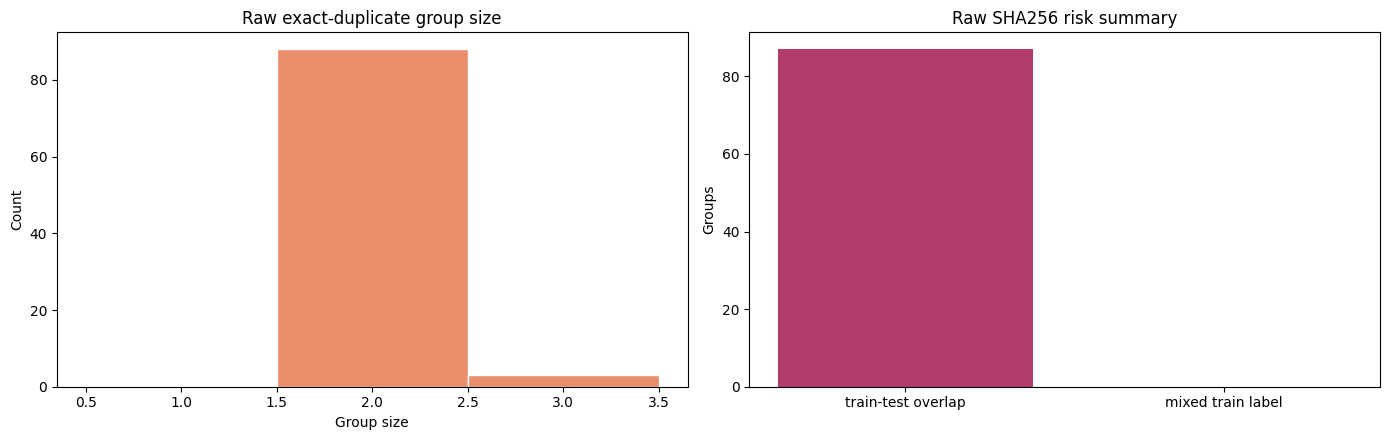

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
dup_sizes = df_sha_groups['size'].to_numpy() if not df_sha_groups.empty else np.array([])
if len(dup_sizes):
    bins = np.arange(0.5, dup_sizes.max() + 1.5, 1.0)
    axes[0].hist(dup_sizes, bins=bins, color=EDA_PALETTE[0], edgecolor='white')
axes[0].set_title('Raw exact-duplicate group size')
axes[0].set_xlabel('Group size')
axes[0].set_ylabel('Count')
overlap_counts = [
    int((df_sha_groups['has_train_test_overlap'] == 1).sum()) if not df_sha_groups.empty else 0,
    int((df_sha_groups['is_mixed_train_label'] == 1).sum()) if not df_sha_groups.empty else 0,
]
axes[1].bar(['train-test overlap', 'mixed train label'], overlap_counts, color=[EDA_PALETTE[3], EDA_PALETTE[4]])
axes[1].set_title('Raw SHA256 risk summary')
axes[1].set_ylabel('Groups')
plt.tight_layout()
plt.show()

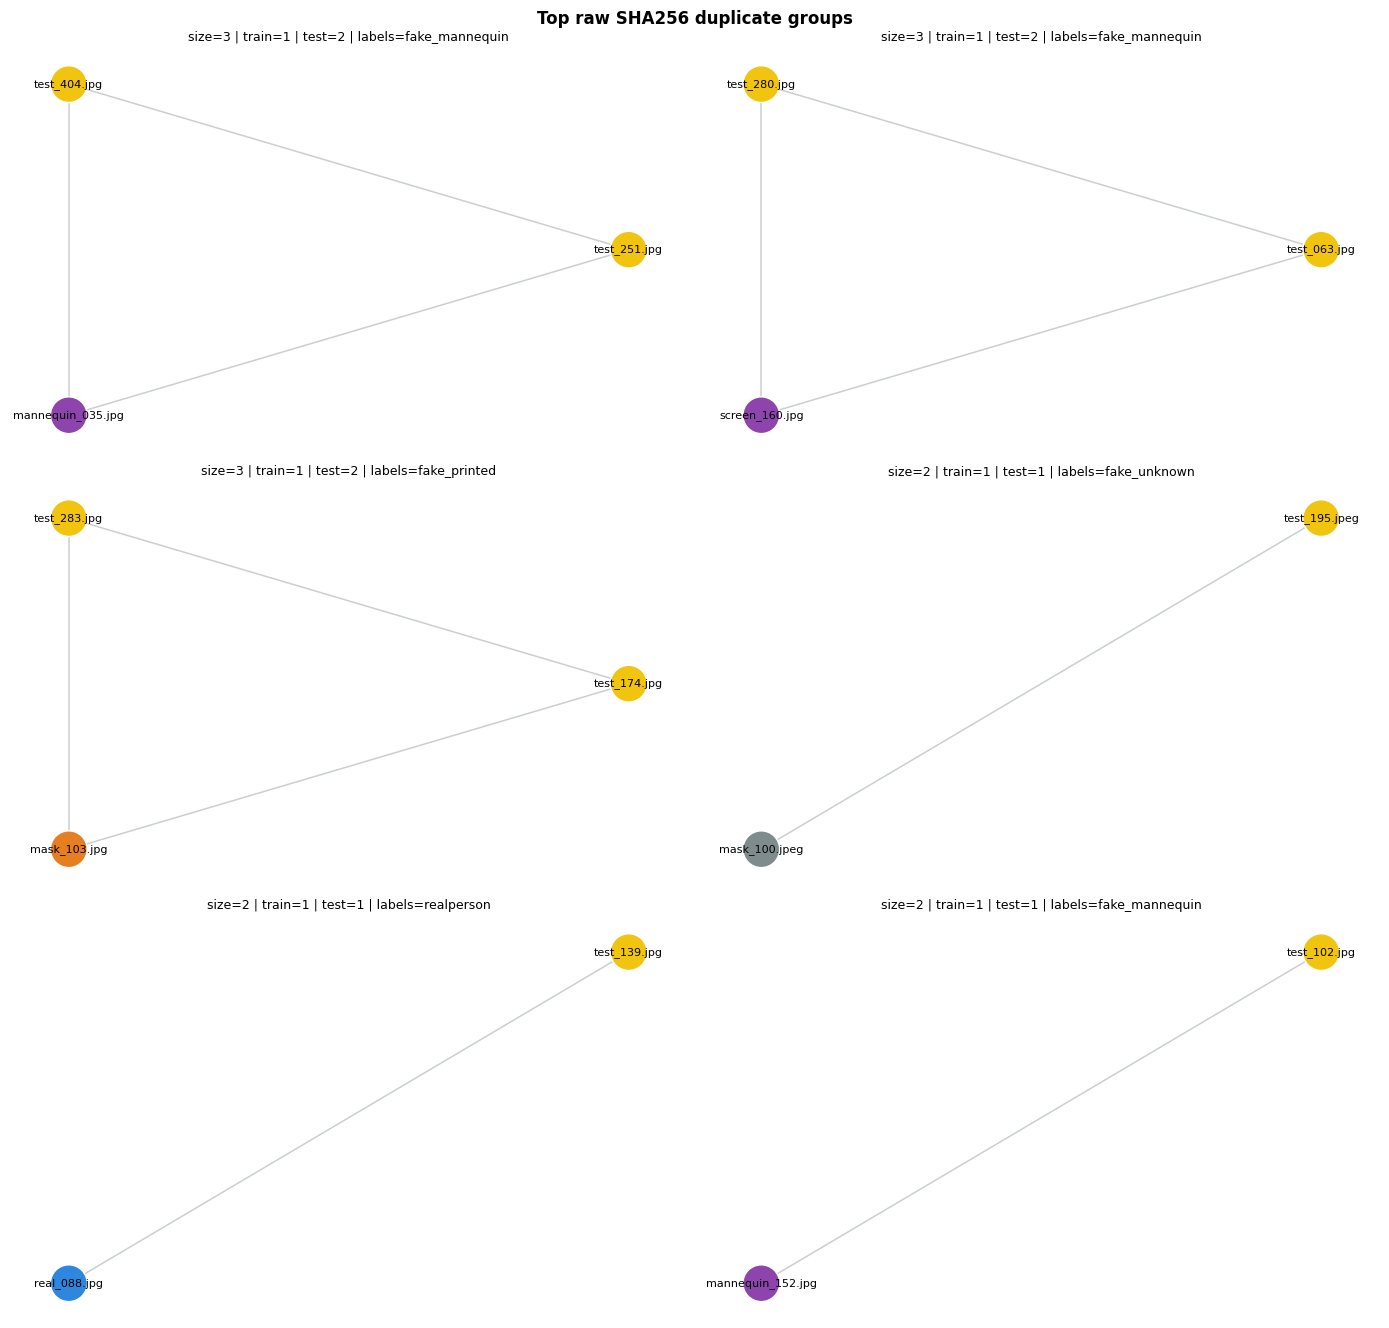

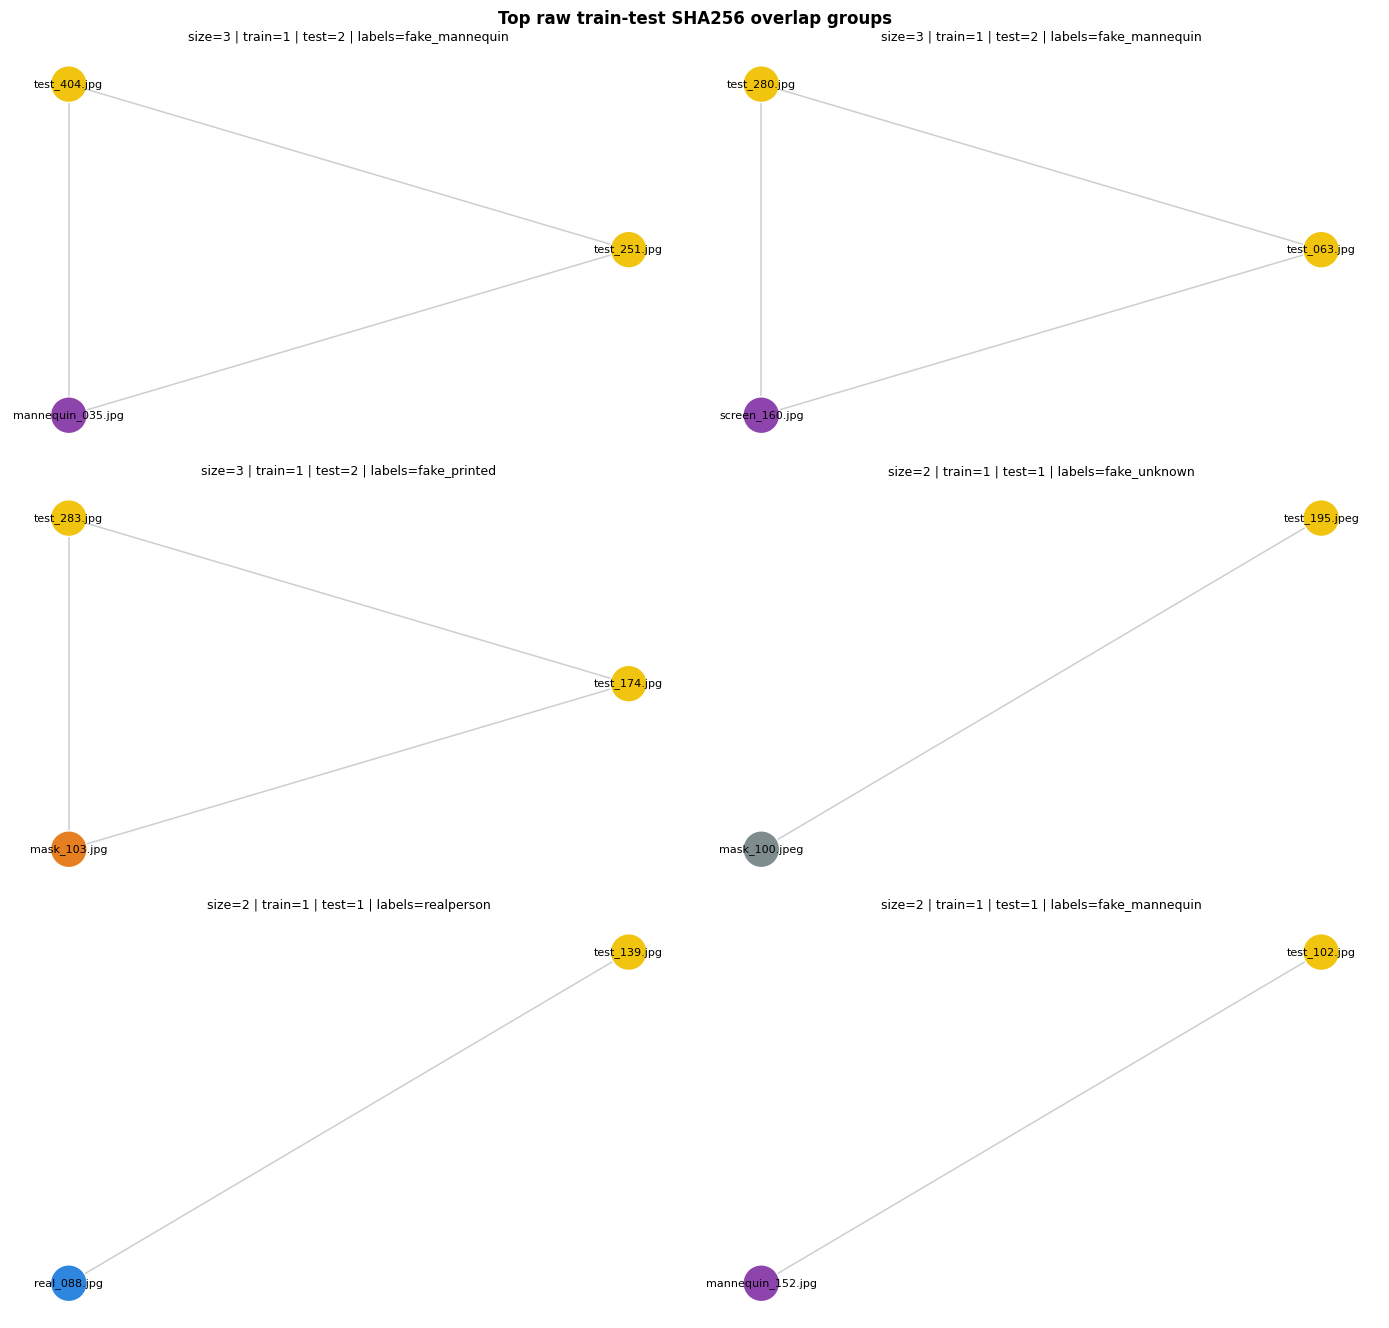

In [ ]:
def draw_sha256_groups(groups_df, df_members, title, top_n=6):
    if groups_df.empty:
        print('No groups to plot.')
        return
    plot_df = groups_df.sort_values(['size', 'sha256'], ascending=[False, True]).head(top_n)
    ncols = 2 if len(plot_df) > 1 else 1
    nrows = int(np.ceil(len(plot_df) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(14, max(4.5, nrows * 4.5)))
    axes = np.atleast_1d(axes).reshape(-1)
    node_label_lookup = df_members.set_index('node')['label'].to_dict()
    for ax, row in zip(axes, plot_df.itertuples(index=False)):
        members = row.members.split('|')
        G = nx.complete_graph(members)
        pos = nx.circular_layout(G)
        colors = []
        labels = {}
        for node in G.nodes():
            src, fname = node.split('::', 1)
            key = 'test' if src == 'test' else node_label_lookup.get(node, '')
            colors.append(SHA256_COLORS.get(key, '#34495e'))
            labels[node] = fname[:18]
        nx.draw_networkx_edges(G, pos, ax=ax, edge_color='#bdc3c7', width=1.1, alpha=0.8)
        nx.draw_networkx_nodes(G, pos, ax=ax, node_color=colors, node_size=700, edgecolors='white', linewidths=1.0)
        nx.draw_networkx_labels(G, pos, labels=labels, font_size=8, ax=ax)
        ax.set_title(f'size={int(row.size)} | train={int(row.n_train)} | test={int(row.n_test)} | labels={row.train_labels or "-"}', fontsize=9)
        ax.axis('off')
    for ax in axes[len(plot_df):]:
        ax.axis('off')
    fig.suptitle(title, fontsize=12, fontweight='bold')
    plt.tight_layout()
    plt.show()

draw_sha256_groups(df_sha_groups, df_sha, 'Top raw SHA256 duplicate groups')
draw_sha256_groups(df_sha_groups[df_sha_groups['has_train_test_overlap'] == 1], df_sha, 'Top raw train-test SHA256 overlap groups')

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

# Prapemrosesan dan Augmentasi <a name="4"></a>

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

Bagian ini mendefinisikan *pipeline* augmentasi data menggunakan *Albumentations*. Augmentasi dipilih berdasarkan karakteristik dataset untuk meningkatkan generalisasi model tanpa mengubah informasi tekstur permukaan yang krusial untuk membedakan kelas serangan.

## Justifikasi Augmentasi

Augmentasi geometri dipilih berdasarkan analisis distribusi orientasi dataset:

- **`RandomRotate90`** -- wajah dapat muncul dalam berbagai orientasi; rotasi 90° tidak mengubah tekstur permukaan
- **`ColorJitter`** -- menambah variasi pencahayaan dan warna untuk meningkatkan ketahanan terhadap kondisi pengambilan gambar yang berbeda

Augmentasi yang *tidak* digunakan:
- **Blur/Noise berat** -- dapat menghilangkan sinyal tekstur mikro (pori kulit, pola *halftone*) yang krusial
- **CutOut/GridMask** -- menyembunyikan area wajah yang menjadi sinyal utama klasifikasi

---

## Transformasi Training

In [ ]:
def get_transforms(img_size: int, mode: str = 'train') -> A.Compose:
    if mode == 'train':
        return A.Compose([
            A.Resize(img_size, img_size),
            A.RandomRotate90(p=0.75),
            A.ColorJitter(brightness=0.3, contrast=0.3,
                          saturation=0.2, hue=0.05, p=0.6),
            A.Normalize(mean=CFG.IMAGENET_MEAN, std=CFG.IMAGENET_STD),
            ToTensorV2(),
        ])
    return A.Compose([
        A.Resize(img_size, img_size),
        A.Normalize(mean=CFG.IMAGENET_MEAN, std=CFG.IMAGENET_STD),
        ToTensorV2(),
    ])

train_transform = get_transforms(CFG.IMG_SIZE, 'train')
val_transform   = get_transforms(CFG.IMG_SIZE, 'val')
print('Transformasi training dan validasi berhasil dibuat.')


Transformasi training dan validasi berhasil dibuat.


---

## Transformasi Validasi dan Inferensi

Transformasi validasi hanya melakukan *resize* dan normalisasi tanpa augmentasi, agar evaluasi menggunakan gambar asli yang merepresentasikan kondisi nyata. Transformasi yang sama digunakan saat inferensi *test set*.

---

## Visualisasi Augmentasi

Gambar asli ditampilkan bersama tiga varian augmentasi untuk memverifikasi bahwa transformasi geometri tidak merusak tekstur permukaan yang menjadi sinyal utama anti-spoofing.

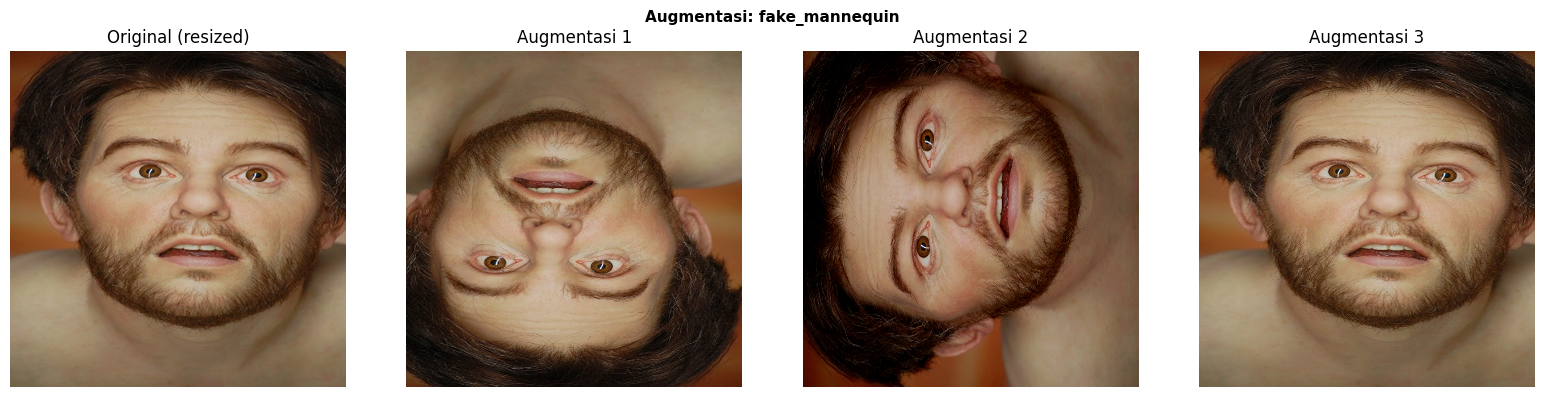

In [ ]:
sample_path, sample_label = raw_train_pairs[0]
orig_np = np.array(load_rgb_image(sample_path))

aug_imgs = []
for _ in range(3):
    aug = get_transforms(CFG.IMG_SIZE, 'train')(image=orig_np)
    t   = aug['image']
    mean = torch.tensor(CFG.IMAGENET_MEAN).view(3, 1, 1)
    std  = torch.tensor(CFG.IMAGENET_STD).view(3, 1, 1)
    vis  = (t * std + mean).clamp(0, 1).permute(1, 2, 0).numpy()
    aug_imgs.append(vis)

orig_resized = np.array(
    Image.fromarray(orig_np).resize((CFG.IMG_SIZE, CFG.IMG_SIZE))
)

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, img, title in zip(
    axes,
    [orig_resized] + aug_imgs,
    ['Original (resized)', 'Augmentasi 1', 'Augmentasi 2', 'Augmentasi 3']
):
    ax.imshow(np.clip(img, 0, 1) if img.dtype != np.uint8 else img)
    ax.set_title(title)
    ax.axis('off')

fig.suptitle(f'Augmentasi: {CFG.CLASS_NAMES[sample_label]}',
             fontsize=11, fontweight='bold')
plt.tight_layout()
plt.savefig(CFG.OUTPUT_DIR / '04_augmentation_vis.png', dpi=100, bbox_inches='tight')
plt.show()


<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

# Pembagian Data dan DataLoader <a name="5"></a>

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

*Stratified K-Fold* membagi dataset menjadi 5 *fold* dengan distribusi kelas yang merata. Fold 0 digunakan sebagai *validation set*, sementara fold 1–4 digunakan untuk *training*. Pendekatan ini memberikan estimasi kinerja yang lebih stabil dibandingkan *random split* biasa.

---

## Kelas Dataset

Kelas `FaceDataset` menangani pemuatan gambar dan penerapan transformasi *Albumentations*. Gambar dikonversi ke NumPy array sebelum diproses karena *Albumentations* menggunakan format NumPy secara native. Kelas ini mendukung mode inferensi (tanpa label).

In [ ]:
class FaceDataset(Dataset):
    def __init__(self, pairs, transform=None, has_labels: bool = True):
        self.paths      = [str(p) for p, _ in pairs] if has_labels else [str(p) for p in pairs]
        self.labels     = [i for _, i in pairs] if has_labels else None
        self.transform  = transform
        self.has_labels = has_labels

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, idx):
        img = np.array(Image.open(self.paths[idx]).convert('RGB'))
        if self.transform:
            img = self.transform(image=img)['image']
        if self.has_labels:
            return img, self.labels[idx]
        return img


---

## Split Berbasis Stratified K-Fold

*Stratified K-Fold* memastikan setiap *fold* memiliki distribusi kelas yang proporsional dengan dataset keseluruhan. Fold 0 difungsikan sebagai *validation set* untuk mengevaluasi performa model selama pelatihan.

In [ ]:
all_paths  = [p for p, _ in raw_train_pairs]
all_labels = [i for _, i in raw_train_pairs]

skf = StratifiedKFold(n_splits=CFG.NUM_FOLDS, shuffle=True,
                      random_state=CFG.SEED)
fold_assignments = np.full(len(all_paths), -1, dtype=int)
for fold, (_, val_idx) in enumerate(skf.split(all_paths, all_labels)):
    fold_assignments[val_idx] = fold

tr_pairs = [(all_paths[i], all_labels[i])
            for i in range(len(all_paths)) if fold_assignments[i] != CFG.TRAIN_FOLD]
va_pairs = [(all_paths[i], all_labels[i])
            for i in range(len(all_paths)) if fold_assignments[i] == CFG.TRAIN_FOLD]

print(f'Train: {len(tr_pairs)} | Val: {len(va_pairs)}')
for idx, cls in enumerate(CFG.CLASS_NAMES):
    n_tr = sum(1 for _, i in tr_pairs if i == idx)
    n_va = sum(1 for _, i in va_pairs if i == idx)
    print(f'  {cls:20s}: train={n_tr}  val={n_va}')


Train: 1179 | Val: 295
  fake_mannequin      : train=156  val=39
  fake_mask           : train=208  val=53
  fake_printed        : train=86  val=21
  fake_screen         : train=153  val=38
  fake_unknown        : train=256  val=64
  realperson          : train=320  val=80


---

## Split CSVs

Hasil pembagian *fold* disimpan ke dua berkas CSV untuk referensi dan reprodusibilitas eksperimen.

In [ ]:
df_train_split = pd.DataFrame([
    {'filename': Path(p).name, 'class': CFG.CLASS_NAMES[i], 'split': 'train'}
    for p, i in tr_pairs
])
df_val_split = pd.DataFrame([
    {'filename': Path(p).name, 'class': CFG.CLASS_NAMES[i], 'split': 'val'}
    for p, i in va_pairs
])
df_train_split.to_csv(CFG.OUTPUT_DIR / 'train_split.csv', index=False)
df_val_split.to_csv(CFG.OUTPUT_DIR   / 'val_split.csv',   index=False)
print(f'Disimpan: train_split.csv ({len(df_train_split)}), '
      f'val_split.csv ({len(df_val_split)})')


Disimpan: train_split.csv (1179), val_split.csv (295)


---

## Visualisasi Split

Visualisasi berikut merangkum distribusi *training* dan *validation set* per kelas untuk memverifikasi bahwa *Stratified K-Fold* berhasil mempertahankan proporsi kelas.

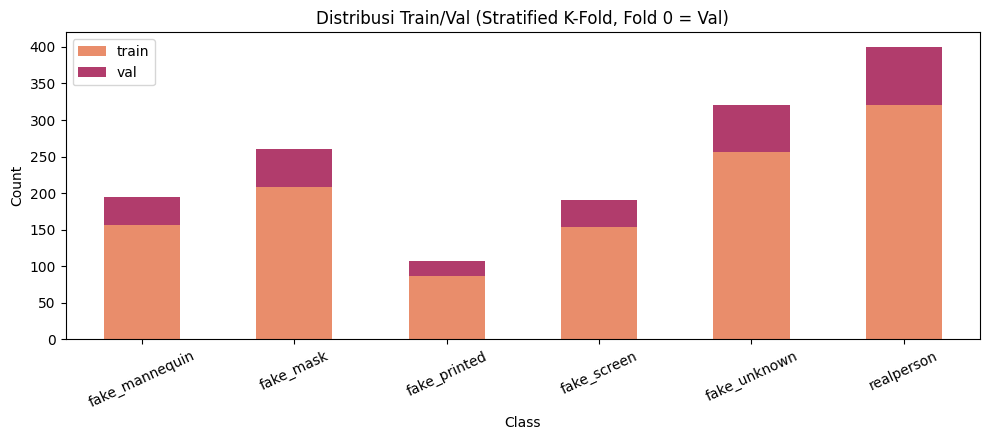

In [ ]:
split_plot_df = pd.DataFrame({
    'train': [sum(1 for _, i in tr_pairs if i == idx) for idx in range(CFG.N_CLASSES)],
    'val':   [sum(1 for _, i in va_pairs if i == idx) for idx in range(CFG.N_CLASSES)],
}, index=CFG.CLASS_NAMES)
fig, ax = plt.subplots(figsize=(10, 4.5))
split_plot_df.plot(kind='bar', stacked=True, ax=ax,
                   color=[EDA_PALETTE[0], EDA_PALETTE[3]])
ax.set_title('Distribusi Train/Val (Stratified K-Fold, Fold 0 = Val)')
ax.set_ylabel('Count')
ax.set_xlabel('Class')
ax.tick_params(axis='x', rotation=25)
plt.tight_layout()
plt.savefig(CFG.OUTPUT_DIR / '05_split_distribution.png', dpi=120, bbox_inches='tight')
plt.show()


---

## Bobot Kelas dan DataLoader

*Class weights* dihitung berdasarkan frekuensi invers untuk menangani ketidakseimbangan kelas. Bobot ini digunakan dalam fungsi *loss* agar model tidak bias terhadap kelas yang lebih banyak. DataLoader dibuat dengan `pin_memory=True` untuk transfer data GPU yang lebih cepat.

In [ ]:
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {DEVICE}')

# Class weights (inverse frequency, dihitung dari training set)
label_counts = torch.zeros(CFG.N_CLASSES)
for _, lbl in tr_pairs:
    label_counts[lbl] += 1
class_weights = 1.0 / (label_counts + 1e-6)
class_weights = class_weights / class_weights.sum() * CFG.N_CLASSES
class_weights = class_weights.to(DEVICE)
print('Bobot kelas:', {
    CFG.CLASS_NAMES[i]: f'{class_weights[i].item():.3f}'
    for i in range(CFG.N_CLASSES)
})

# DataLoaders
train_ds = FaceDataset(tr_pairs, transform=train_transform)
val_ds   = FaceDataset(va_pairs, transform=val_transform)

train_loader = DataLoader(
    train_ds, batch_size=CFG.BATCH_SIZE, shuffle=True,
    num_workers=CFG.NUM_WORKERS, pin_memory=True
)
val_loader = DataLoader(
    val_ds, batch_size=CFG.BATCH_SIZE * 2, shuffle=False,
    num_workers=CFG.NUM_WORKERS, pin_memory=True
)
print(f'Train batches: {len(train_loader)} | Val batches: {len(val_loader)}')


Device: cuda
Bobot kelas: {'fake_mannequin': '1.056', 'fake_mask': '0.792', 'fake_printed': '1.916', 'fake_screen': '1.077', 'fake_unknown': '0.644', 'realperson': '0.515'}
Train batches: 148 | Val batches: 19


<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

# Pemodelan <a name="6"></a>

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

Arsitektur yang digunakan adalah DINOv2-Large (ViT-L/14) dengan *partial fine-tuning* pada enam blok *encoder* terakhir. *Head* klasifikasi dua lapisan ditambahkan di atas token CLS *backbone*. Pendekatan ini menyeimbangkan antara memanfaatkan representasi yang sudah dipelajari DINOv2 dan mengadaptasi fitur domain-spesifik untuk deteksi serangan presentasi wajah.

## Arsitektur Model

Token CLS dari lapisan terakhir *backbone* merangkum representasi global wajah. Token ini kemudian dimasukkan ke *head* klasifikasi yang terdiri dari:

1. `LayerNorm(1024)` -- normalisasi fitur sebelum proyeksi
2. `Linear(1024, 512)` + `GELU` + `Dropout(0.3)` -- proyeksi non-linear
3. `Linear(512, 6)` -- prediksi logit untuk 6 kelas

Enam blok *encoder* terakhir (lapisan 18–23 dari 24) dibuka untuk *fine-tuning* dengan LR lebih kecil, sedangkan lapisan sebelumnya tetap dibekukan untuk menjaga representasi umum yang dipelajari DINOv2.

In [ ]:
class DINOv2Classifier(nn.Module):
    """DINOv2 ViT-L/14 backbone dengan head klasifikasi dua lapisan.
    Enam blok encoder terakhir (18-23) dibuka untuk fine-tuning parsial.
    """

    def __init__(self, model_name: str, num_classes: int, dropout: float = 0.3):
        super().__init__()
        self.backbone = AutoModel.from_pretrained(model_name)
        hidden = self.backbone.config.hidden_size  # 1024 untuk ViT-L/14
        self.head = nn.Sequential(
            nn.LayerNorm(hidden),
            nn.Linear(hidden, 512),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(512, num_classes),
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        out = self.backbone(x)
        cls_token = out.last_hidden_state[:, 0]  # [B, hidden]
        return self.head(cls_token)


model = DINOv2Classifier(CFG.MODEL_NAME, CFG.N_CLASSES,
                         dropout=CFG.DROPOUT).to(DEVICE)

# Bekukan seluruh backbone, lalu buka 6 blok encoder terakhir (18-23)
for param in model.backbone.parameters():
    param.requires_grad = False
for layer in model.backbone.encoder.layer[18:]:
    for param in layer.parameters():
        param.requires_grad = True

total     = sum(p.numel() for p in model.parameters()) / 1e6
trainable = sum(p.numel() for p in model.parameters() if p.requires_grad) / 1e6
print(f'Total: {total:.1f}M  |  Trainable: {trainable:.1f}M')


config.json:   0%|          | 0.00/549 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/1.22G [00:00<?, ?B/s]

Loading weights:   0%|          | 0/439 [00:00<?, ?it/s]

Total: 304.9M  |  Trainable: 76.1M


---

## Inspeksi Arsitektur Backbone

Sel ini mencetak struktur modul *backbone* untuk memverifikasi jalur atribut dan mengonfirmasi bahwa lapisan 18–23 berhasil dibuka untuk *fine-tuning*.

In [ ]:
print('=== backbone named_children ===')
for _n, _m in model.backbone.named_children():
    print(f'  {_n}: {type(_m).__name__}')

print()
print('=== parameter groups ===')
n_frozen_bb  = sum(1 for p in model.backbone.parameters() if not p.requires_grad)
n_train_bb   = sum(1 for p in model.backbone.parameters() if p.requires_grad)
print(f'  Backbone frozen   : {n_frozen_bb}')
print(f'  Backbone trainable: {n_train_bb}')
print(f'  Head trainable    : {sum(1 for _ in model.head.parameters())}')


=== backbone named_children ===
  embeddings: Dinov2Embeddings
  encoder: Dinov2Encoder
  layernorm: LayerNorm

=== parameter groups ===
  Backbone frozen   : 331
  Backbone trainable: 108
  Head trainable    : 6


---

## Metrik

Metrik utama yang digunakan adalah *macro F1-score*, yang memberikan bobot setara pada setiap kelas terlepas dari jumlah sampelnya. Ini penting mengingat potensi ketidakseimbangan kelas pada dataset serangan presentasi.

In [ ]:
def compute_f1(preds, targets, average='macro'):
    return f1_score(targets, preds, average=average, zero_division=0)

def macro_f1(preds, targets):
    return compute_f1(preds, targets, average='macro')

---

## Utilitas Pelatihan

### EarlyStopping dan Simpan Checkpoint

In [ ]:
class EarlyStopping:
    def __init__(self, patience: int):
        self.patience    = patience
        self.best_metric = -1.0
        self.best_train_metric = -1.0
        self.counter     = 0
        self.should_stop = False
        self.best_state  = None

    def step(self, metric, train_metric, model):
        improved = (metric, train_metric) > (self.best_metric, self.best_train_metric)
        if improved:
            self.best_metric = metric
            self.best_train_metric = train_metric
            self.counter     = 0
            self.best_state  = {k: v.cpu().clone() for k, v in model.state_dict().items()}
            return True
        else:
            self.counter += 1
            if self.counter >= self.patience:
                self.should_stop = True
            return False


def save_checkpoint(model, optimizer, epoch, metric, train_metric, path):
    torch.save({
        'epoch': epoch,
        'model_state_dict': model.state_dict(),
        'optimizer_state_dict': optimizer.state_dict(),
        'metric': metric,
        'train_metric': train_metric,
    }, path)
    print(
        f'  Checkpoint disimpan: epoch {epoch}  '
        f'val_F1={metric:.4f}  train_F1={train_metric:.4f} -> {path.name}'
    )

### Scheduler: CosineAnnealingLR

*CosineAnnealingLR* menurunkan *learning rate* mengikuti fungsi kosinus dari nilai awal ke nilai minimum (`eta_min=1e-7`). Pendekatan ini sederhana dan efektif karena bobot *backbone* sudah terlatih dari *pre-training* DINOv2, sehingga tidak memerlukan fase *warmup* yang panjang.

### `train_one_epoch`

In [ ]:
def train_one_epoch(model, loader, optimizer, scheduler, scaler, device,
                    criterion, accum_steps=1):
    model.train()
    total_loss, all_preds, all_labels = 0.0, [], []
    optimizer.zero_grad()

    for step, (imgs, labels) in enumerate(
        tqdm(loader, desc='  Train', leave=True)
    ):
        imgs, labels = imgs.to(device), labels.to(device)
        with torch.cuda.amp.autocast():
            logits = model(imgs)
            loss   = criterion(logits, labels) / accum_steps

        scaler.scale(loss).backward()

        if (step + 1) % accum_steps == 0:
            scaler.unscale_(optimizer)
            nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            scaler.step(optimizer)
            scaler.update()
            scheduler.step()
            optimizer.zero_grad()

        total_loss += loss.item() * accum_steps
        all_preds.extend(logits.argmax(1).cpu().tolist())
        all_labels.extend(labels.cpu().tolist())

    avg_loss = total_loss / len(loader)
    f1       = macro_f1(all_preds, all_labels)
    return avg_loss, f1, all_preds, all_labels


### `validate`

In [ ]:
@torch.no_grad()
def validate(model, loader, device, criterion):
    model.eval()
    total_loss, all_preds, all_labels = 0.0, [], []

    for imgs, labels in tqdm(loader, desc='  Val  ', leave=True):
        imgs, labels = imgs.to(device), labels.to(device)
        with torch.cuda.amp.autocast():
            logits = model(imgs)
            loss   = criterion(logits, labels)
        total_loss += loss.item()
        all_preds.extend(logits.argmax(1).cpu().tolist())
        all_labels.extend(labels.cpu().tolist())

    avg_loss = total_loss / len(loader)
    f1       = macro_f1(all_preds, all_labels)
    return avg_loss, f1, all_preds, all_labels


---

## Optimizer dan Training

In [ ]:
criterion = nn.CrossEntropyLoss(weight=class_weights)

# Dua LR berbeda: lebih kecil untuk backbone, lebih besar untuk head
optimizer = torch.optim.AdamW([
    {'params': [p for p in model.backbone.parameters() if p.requires_grad],
     'lr': CFG.LR},
    {'params': model.head.parameters(),
     'lr': CFG.HEAD_LR},
], weight_decay=CFG.WEIGHT_DECAY)

total_steps = CFG.EPOCHS * len(train_loader) // CFG.ACCUM_STEPS
scheduler   = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer, T_max=total_steps, eta_min=1e-7
)

scaler     = torch.cuda.amp.GradScaler()
early_stop = EarlyStopping(patience=CFG.EARLY_STOP_PATIENCE)

print(f'LR backbone : {CFG.LR}')
print(f'LR head     : {CFG.HEAD_LR}')
print(f'Total steps : {total_steps}')


LR backbone : 2e-05
LR head     : 0.0001
Total steps : 555


  Val  : 100%|██████████| 19/19 [00:16<00:00,  1.16it/s]


Epoch   1/15  tr_loss=0.5469  tr_f1=0.8337  va_loss=0.2071  va_f1=0.9280
  train: mannequi=0.88  mask=0.77  printed=0.77  screen=0.83  unknown=0.92  realpers=0.83
  val  : mannequi=0.95  mask=0.87  printed=0.95  screen=0.97  unknown=0.94  realpers=0.89
  Checkpoint disimpan: epoch 1  val_F1=0.9280  train_F1=0.8337 -> dinov2_large_v1_stratifiedkfold_best.pth


  Val  : 100%|██████████| 19/19 [00:15<00:00,  1.19it/s]


Epoch   2/15  tr_loss=0.1561  tr_f1=0.9501  va_loss=0.1094  va_f1=0.9771
  train: mannequi=0.97  mask=0.89  printed=0.96  screen=0.97  unknown=0.97  realpers=0.92
  val  : mannequi=0.99  mask=0.96  printed=1.00  screen=0.97  unknown=0.98  realpers=0.96
  Checkpoint disimpan: epoch 2  val_F1=0.9771  train_F1=0.9501 -> dinov2_large_v1_stratifiedkfold_best.pth


  Val  : 100%|██████████| 19/19 [00:15<00:00,  1.19it/s]


...

  Val  : 100%|██████████| 19/19 [00:16<00:00,  1.19it/s]


Epoch  11/15  tr_loss=0.0031  tr_f1=0.9987  va_loss=0.1818  va_f1=0.9684
  train: mannequi=1.00  mask=1.00  printed=1.00  screen=1.00  unknown=1.00  realpers=1.00
  val  : mannequi=0.97  mask=0.95  printed=0.95  screen=0.99  unknown=0.98  realpers=0.97


  Val  : 100%|██████████| 19/19 [00:16<00:00,  1.17it/s]


Epoch  12/15  tr_loss=0.0003  tr_f1=1.0000  va_loss=0.1793  va_f1=0.9684
  train: mannequi=1.00  mask=1.00  printed=1.00  screen=1.00  unknown=1.00  realpers=1.00
  val  : mannequi=0.97  mask=0.95  printed=0.95  screen=0.99  unknown=0.98  realpers=0.97
Early stopping pada epoch 12.

=== Misclassified Train Images ===


Total: 0 / 1179 misclassified


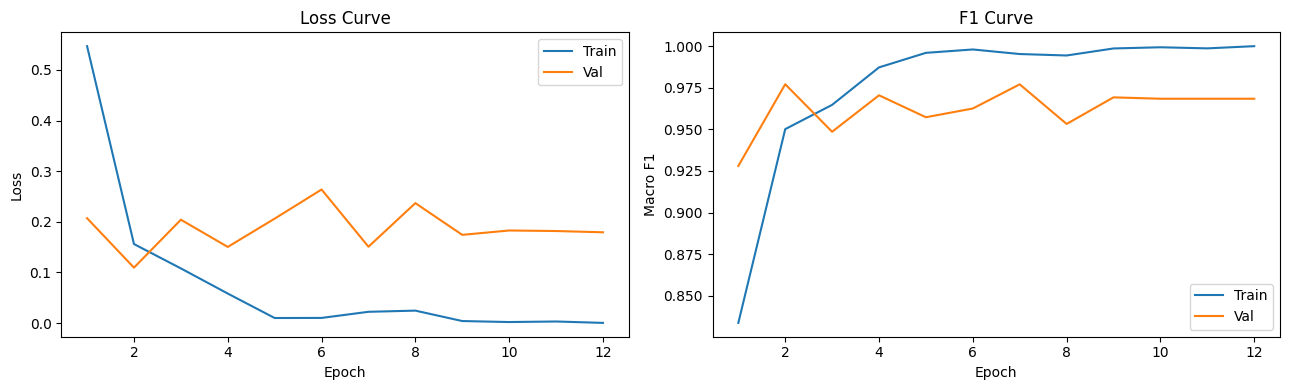


Best val Macro F1: 0.9771


In [ ]:
metrics_log = []
_cls_abbr = [c.replace('fake_', '')[:8] for c in CFG.CLASS_NAMES]

if CFG.RUN_NAME != 'INFERENCE':
    for epoch in range(CFG.EPOCHS):
        tr_loss, tr_f1, tr_preds, tr_labels = train_one_epoch(
            model, train_loader, optimizer, scheduler, scaler, DEVICE,
            criterion, accum_steps=CFG.ACCUM_STEPS,
        )
        va_loss, va_f1, va_preds, va_labels = validate(
            model, val_loader, DEVICE, criterion
        )

        _tr_pcf1 = f1_score(tr_labels, tr_preds, average=None, zero_division=0)
        _va_pcf1 = f1_score(va_labels, va_preds, average=None, zero_division=0)

        metrics_log.append({
            'epoch': epoch + 1,
            'tr_loss': tr_loss, 'tr_f1': tr_f1,
            'va_loss': va_loss, 'va_f1': va_f1,
        })
        print(
            f'Epoch {epoch+1:3d}/{CFG.EPOCHS}  '
            f'tr_loss={tr_loss:.4f}  tr_f1={tr_f1:.4f}  '
            f'va_loss={va_loss:.4f}  va_f1={va_f1:.4f}'
        )
        print('  train: ' + '  '.join(
            f'{_cls_abbr[i]}={_tr_pcf1[i]:.2f}' for i in range(CFG.N_CLASSES)
        ))
        print('  val  : ' + '  '.join(
            f'{_cls_abbr[i]}={_va_pcf1[i]:.2f}' for i in range(CFG.N_CLASSES)
        ))

        improved = early_stop.step(va_f1, tr_f1, model)
        if improved:
            save_checkpoint(model, optimizer, epoch + 1,
                            va_f1, tr_f1, CFG.CHECKPOINT_PATH)
        if early_stop.should_stop:
            print(f'Early stopping pada epoch {epoch+1}.')
            break

    # -- Misclassified train images (eval pass, tanpa augmentasi) ----------
    print('\n=== Misclassified Train Images ===')
    _tr_eval_loader = DataLoader(
        FaceDataset(tr_pairs, transform=val_transform),
        batch_size=CFG.BATCH_SIZE, shuffle=False,
        num_workers=CFG.NUM_WORKERS, pin_memory=True,
    )
    _tr_eval_preds = []
    model.eval()
    with torch.no_grad():
        for _imgs, _ in tqdm(_tr_eval_loader, desc='  Train eval', leave=False):
            with torch.cuda.amp.autocast():
                _logits = model(_imgs.to(DEVICE))
            _tr_eval_preds.extend(_logits.argmax(1).cpu().tolist())
    _misclassified_tr = [
        (Path(p).name, CFG.CLASS_NAMES[true_i], CFG.CLASS_NAMES[pred_i])
        for (p, true_i), pred_i in zip(tr_pairs, _tr_eval_preds)
        if true_i != pred_i
    ]
    print(f'Total: {len(_misclassified_tr)} / {len(tr_pairs)} misclassified')
    for _fname, _true, _pred in _misclassified_tr:
        print(f'  {_fname:35s}  true={_true:20s}  pred={_pred}')

    # Kurva pelatihan
    df_log = pd.DataFrame(metrics_log)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))
    ax1.plot(df_log['epoch'], df_log['tr_loss'], label='Train')
    ax1.plot(df_log['epoch'], df_log['va_loss'], label='Val')
    ax1.set_xlabel('Epoch'); ax1.set_ylabel('Loss')
    ax1.set_title('Loss Curve'); ax1.legend()
    ax2.plot(df_log['epoch'], df_log['tr_f1'], label='Train')
    ax2.plot(df_log['epoch'], df_log['va_f1'], label='Val')
    ax2.set_xlabel('Epoch'); ax2.set_ylabel('Macro F1')
    ax2.set_title('F1 Curve'); ax2.legend()
    plt.tight_layout()
    plt.savefig(CFG.OUTPUT_DIR / '05_training_curves.png', dpi=120, bbox_inches='tight')
    plt.show()

    pd.DataFrame(metrics_log).to_csv(CFG.OUTPUT_DIR / 'history.csv', index=False)
    print(f'\nBest val Macro F1: {early_stop.best_metric:.4f}')
else:
    print('RUN_NAME=INFERENCE, pelatihan dilewati.')


<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

# Inferensi dan Submisi <a name="7"></a>

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

Sel-sel berikut memuat *checkpoint* terbaik, mengevaluasi model pada *validation set*, kemudian menjalankan inferensi pada *test set* menggunakan **2-view TTA** (gambar asli + *horizontal flip*). Probabilitas dari kedua *view* dirata-ratakan sebelum dikonversi ke prediksi kelas akhir.

## Muat Checkpoint Terbaik

Apabila *checkpoint* tersedia di Google Drive, berkas dapat diunduh terlebih dahulu menggunakan `gdown` sebelum dimuat ke model. Jika *training* baru saja selesai, *checkpoint* sudah ada di `CFG.OUTPUT_DIR`.

In [ ]:
CKPT_URL = 'https://drive.google.com/uc?id=1uB2P7fp9qkoTisMMSA4uLpAQf5IdTpU8'
if not CFG.CHECKPOINT_PATH.exists():
    gdown.download(CKPT_URL, str(CFG.CHECKPOINT_PATH), quiet=False)


In [ ]:
def load_checkpoint(path, model, optimizer=None):
    ckpt = torch.load(path, map_location='cpu', weights_only=False)
    model.load_state_dict(ckpt['model_state_dict'])
    if optimizer is not None:
        optimizer.load_state_dict(ckpt['optimizer_state_dict'])
    print(f'Checkpoint dimuat: epoch {ckpt["epoch"]}  F1={ckpt["metric"]:.4f}')
    return ckpt

if CFG.RUN_NAME == 'INFERENCE':
    model = DINOv2Classifier(
        model_name=CFG.MODEL_NAME,
        num_classes=CFG.N_CLASSES,
        dropout=CFG.DROPOUT,
    ).to(DEVICE)
    for param in model.backbone.parameters():
        param.requires_grad = False
    for layer in model.backbone.encoder.layer[18:]:
        for param in layer.parameters():
            param.requires_grad = True
    load_checkpoint(CFG.CHECKPOINT_PATH, model)
else:
    print(
        f'Best model already loaded (val F1={early_stop.best_metric:.4f}, '
        f'train F1={early_stop.best_train_metric:.4f})'
    )


Best model already loaded (val F1=0.9771, train F1=0.9501)


---

## Evaluasi Validasi

Laporan klasifikasi dan matriks konfusi memberikan gambaran lengkap tentang performa model per kelas. Kelas dengan *recall* rendah menjadi prioritas perbaikan pada iterasi berikutnya.

In [ ]:
_, val_f1, val_preds, val_labels = validate(model, val_loader, DEVICE, criterion)
print(f'Val Macro F1: {val_f1:.4f}')
print()
print(classification_report(
    val_labels, val_preds, target_names=CFG.CLASS_NAMES, zero_division=0
))

  Val  : 100%|██████████| 19/19 [00:16<00:00,  1.16it/s]

Val Macro F1: 0.9684

                precision    recall  f1-score   support

fake_mannequin       0.97      0.97      0.97        39
     fake_mask       0.93      0.98      0.95        53
  fake_printed       1.00      0.90      0.95        21
   fake_screen       1.00      0.97      0.99        38
  fake_unknown       0.98      0.97      0.98        64
    realperson       0.96      0.97      0.97        80

      accuracy                           0.97       295
     macro avg       0.98      0.96      0.97       295
  weighted avg       0.97      0.97      0.97       295



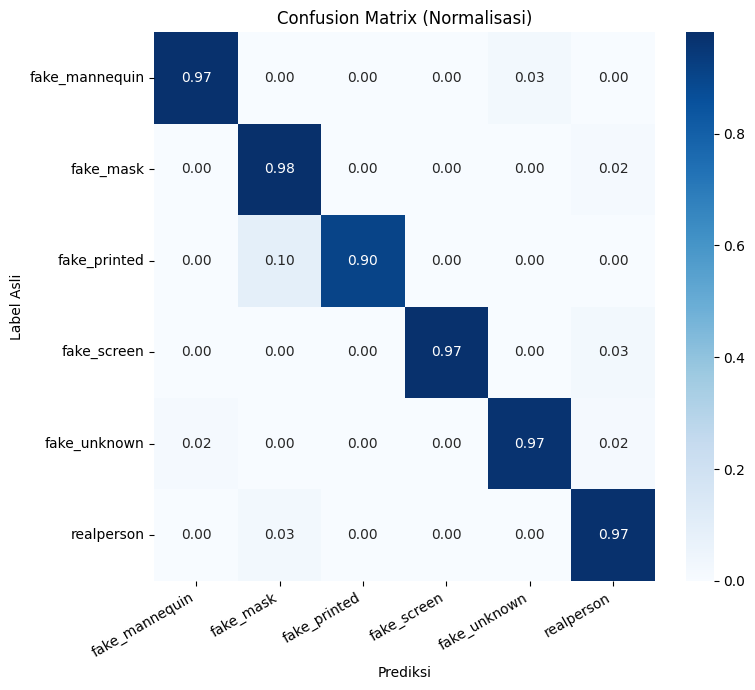

In [ ]:
cm = confusion_matrix(val_labels, val_preds, normalize='true')

fig, ax = plt.subplots(figsize=(8, 7))
sns.heatmap(
    cm, annot=True, fmt='.2f', cmap='Blues',
    xticklabels=CFG.CLASS_NAMES, yticklabels=CFG.CLASS_NAMES,
    ax=ax,
)
ax.set_xlabel('Prediksi')
ax.set_ylabel('Label Asli')
ax.set_title('Confusion Matrix (Normalisasi)')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.savefig(CFG.OUTPUT_DIR / '06_confusion_matrix.png', dpi=120, bbox_inches='tight')
plt.show()

In [ ]:
# Misclassified and correct val samples for XAI analysis
val_errors = [
    (va_pairs[i][0], int(val_labels[i]), int(val_preds[i]))
    for i in range(len(va_pairs))
    if val_preds[i] != val_labels[i]
]
# 2 correct samples per class (12 total for 6-class dataset)
_correct_all = [
    (va_pairs[i][0], int(val_labels[i]), int(val_preds[i]))
    for i in range(len(va_pairs))
    if val_preds[i] == val_labels[i]
]
_per_class = defaultdict(list)
for item in _correct_all:
    cls = item[1]
    if len(_per_class[cls]) < 2:
        _per_class[cls].append(item)
# sorted by class index -- each row (n_cols=2) contains the same class
val_correct = [item for cls in sorted(_per_class) for item in _per_class[cls]]
print(f'Misclassified: {len(val_errors)} / {len(va_pairs)} val samples')
for path, true_l, pred_l in val_errors:
    print(f'  {Path(path).name:40s}  true={CFG.CLASS_NAMES[true_l]:15s}  pred={CFG.CLASS_NAMES[pred_l]}')

Misclassified: 9 / 295 val samples
  mannequin_099.jpeg                        true=fake_mannequin   pred=fake_unknown
  mask_148.jpg                              true=fake_mask        pred=realperson
  printed_093.jpg                           true=fake_printed     pred=fake_mask
  printed_080.jpg                           true=fake_printed     pred=fake_mask
  screen_206.jpg                            true=fake_screen      pred=realperson
  unknown_152.jpeg                          true=fake_unknown     pred=fake_mannequin
  unknown_331.jpg                           true=fake_unknown     pred=realperson
  real_280.jpg                              true=realperson       pred=fake_mask
  real_290.jpeg                             true=realperson       pred=fake_mask


---

## Inferensi Test Set

Inferensi menggunakan **2-view TTA** (gambar asli + *horizontal flip*). Probabilitas dari kedua *view* dirata-ratakan sebelum dikonversi ke prediksi kelas akhir. Strategi TTA ini sederhana namun efektif untuk meningkatkan robustitas prediksi.

In [ ]:
class TestDataset(Dataset):
    """Dataset untuk inferensi -- menerima daftar path gambar."""
    def __init__(self, paths, transform):
        self.paths     = [str(p) for p in paths]
        self.img_ids   = [Path(p).stem for p in paths]
        self.transform = transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, idx):
        img = np.array(Image.open(self.paths[idx]).convert('RGB'))
        img = self.transform(image=img)['image']
        return img, self.img_ids[idx]


In [ ]:
# 2 transform TTA: original + horizontal flip
hflip_transform = A.Compose([
    A.Resize(CFG.IMG_SIZE, CFG.IMG_SIZE),
    A.HorizontalFlip(p=1.0),
    A.Normalize(mean=CFG.IMAGENET_MEAN, std=CFG.IMAGENET_STD),
    ToTensorV2(),
])
tta_transforms = [val_transform, hflip_transform]


@torch.no_grad()
def predict_with_tta(model, paths, tta_tfms):
    probs_list = []
    for tfm in tta_tfms:
        ds     = TestDataset(paths, tfm)
        loader = DataLoader(ds, batch_size=CFG.BATCH_SIZE * 2,
                            num_workers=CFG.NUM_WORKERS, pin_memory=True)
        probs, ids = [], []
        model.eval()
        for imgs, img_ids in tqdm(loader, desc='  Predict', leave=True):
            imgs = imgs.to(DEVICE)
            with torch.cuda.amp.autocast():
                logits = model(imgs)
            probs.append(F.softmax(logits, dim=1).cpu().numpy())
            ids.extend(img_ids)
        probs_list.append(np.concatenate(probs))
    return ids, np.mean(probs_list, axis=0)


all_ids, probs_tta = predict_with_tta(model, test_images, tta_transforms)
all_preds = [CFG.CLASS_NAMES[i] for i in probs_tta.argmax(axis=1).tolist()]
print(f'TTA selesai: {len(all_preds)} gambar, {len(tta_transforms)} views')


  Predict: 100%|██████████| 26/26 [00:26<00:00,  1.00s/it]

TTA selesai: 404 gambar, 2 views


---

## Pembuatan Berkas Submisi

Submisi akhir ditulis langsung dari prediksi model pada *test set* yang sudah diproses.

In [ ]:
df_sub = pd.DataFrame({'id': all_ids, 'label': all_preds})
df_sub = df_sub.sort_values('id').reset_index(drop=True)

assert not df_sub[['id', 'label']].isna().any().any(), 'Terdapat nilai kosong pada submisi'
assert df_sub['label'].isin(CFG.CLASS_NAMES).all(), 'Label tidak valid'

df_sub.to_csv(CFG.SUBMISSION_CSV, index=False)
print(f'Submisi disimpan ke {CFG.SUBMISSION_CSV}')
print(f'Bentuk: {df_sub[["id", "label"]].shape}')
print(df_sub['label'].value_counts())
df_sub.head(10)


Submisi disimpan ke /kaggle/working/dinov2-large/dinov2_large_v1_stratifiedkfold/submission_dinov2_large_v1_stratifiedkfold.csv
Bentuk: (404, 2)
label
realperson        100
fake_screen        74
fake_mask          68
fake_printed       62
fake_mannequin     51
fake_unknown       49
Name: count, dtype: int64


,id,label
0,test_001,fake_screen
1,test_002,fake_mannequin
2,test_003,realperson
3,test_004,realperson
4,test_005,fake_printed
5,test_006,fake_mannequin
6,test_007,fake_mask
7,test_008,fake_mannequin
8,test_009,fake_mask
9,test_010,fake_screen


<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

# Pasca-Analisis <a name="8"></a>

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

## Analisis Kesalahan dan Visualisasi Perhatian (XAI)

Sampel validasi yang salah diklasifikasikan ditampilkan bersama *heatmap* perhatian DINOv2 dari lapisan *encoder* terakhir. Label asli dan prediksi model ditampilkan di atas setiap pasang gambar. Analisis ini memperlihatkan pola kegagalan model: apakah perhatian jatuh pada tekstur yang tepat namun prediksinya tetap salah, atau model berfokus pada area yang tidak relevan seperti latar belakang atau artefak pencahayaan.

`get_attention_map` mengekstraksi peta perhatian dari lapisan *encoder* terakhir DINOv2 menggunakan *forward hook* pada `Dinov2Attention`. Fungsi mengembalikan heatmap `[H_grid, W_grid]` yang merepresentasikan seberapa besar token CLS memperhatikan tiap *patch*. Untuk ViT-L/14 dengan input 336×336 px, ukuran grid adalah 24×24 (576 patch).

Loading weights:   0%|          | 0/439 [00:00<?, ?it/s]

XAI model siap.


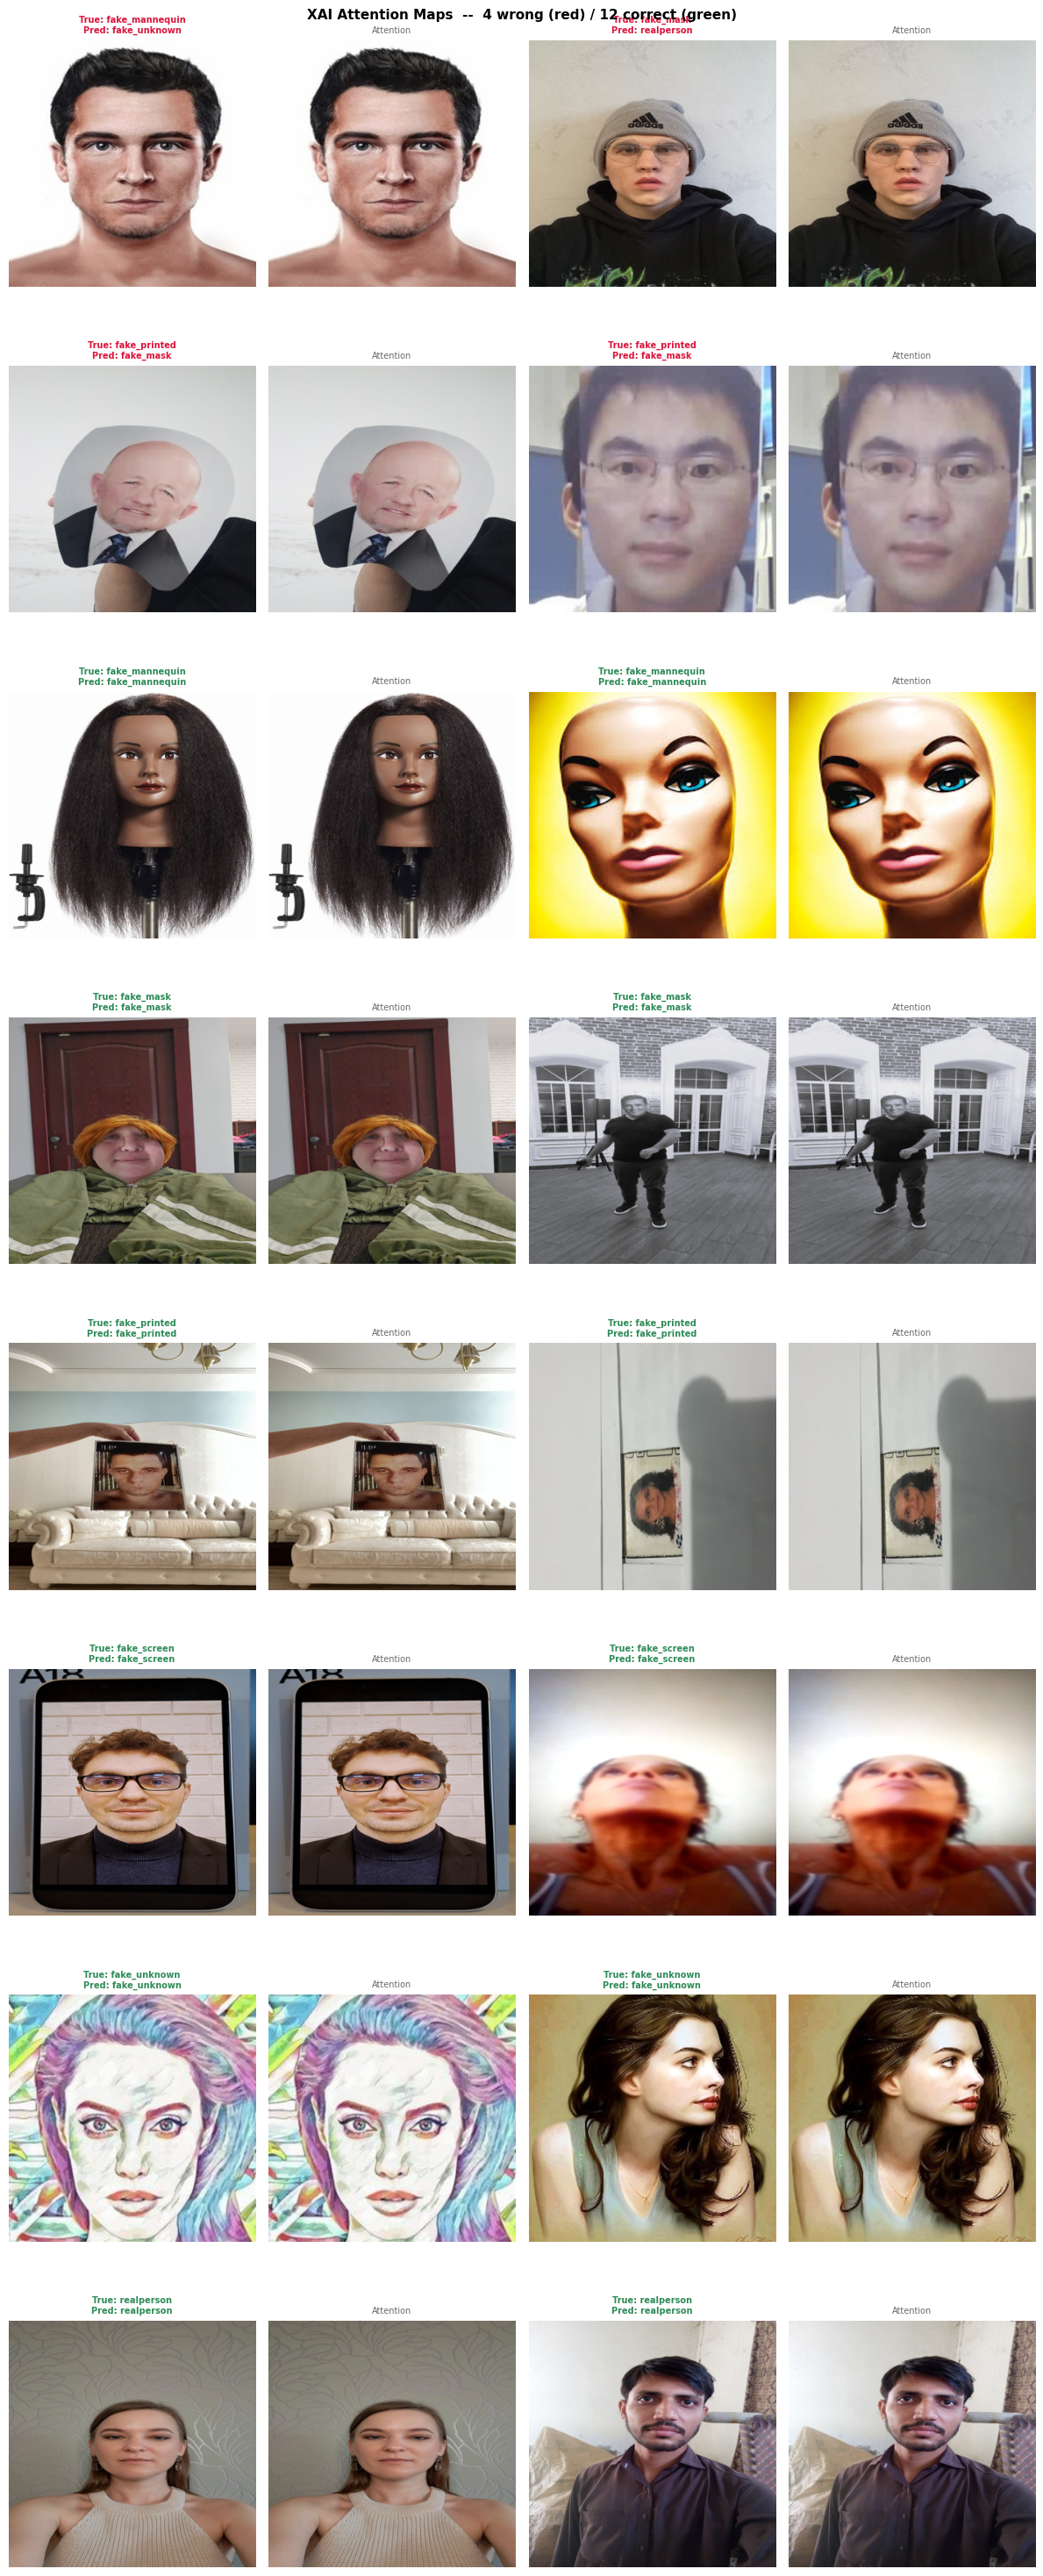

In [ ]:
xai_model = DINOv2Classifier(
    model_name=CFG.MODEL_NAME,
    num_classes=CFG.N_CLASSES,
    dropout=CFG.DROPOUT,
).to(DEVICE)
for param in xai_model.backbone.parameters():
    param.requires_grad = False
for layer in xai_model.backbone.encoder.layer[18:]:
    for param in layer.parameters():
        param.requires_grad = True

if CFG.RUN_NAME == 'INFERENCE' or not hasattr(early_stop, 'best_state'):
    load_checkpoint(CFG.CHECKPOINT_PATH, xai_model)
else:
    xai_model.load_state_dict(early_stop.best_state)
xai_model.eval()
print('XAI model siap.')


def get_attention_map(model, img_tensor):
    attn_store = {}

    def _hook(module, inp, out):
        # Dinov2Attention mengembalikan (context_layer, attention_probs)
        if len(out) > 1 and out[1] is not None:
            attn_store['w'] = out[1]

    hook = xai_model.backbone.encoder.layer[-1].attention.register_forward_hook(_hook)
    with torch.no_grad():
        xai_model.backbone(
            pixel_values=img_tensor.unsqueeze(0).to(DEVICE),
            output_attentions=True,
        )
    hook.remove()
    if 'w' not in attn_store:
        return None
    attn     = attn_store['w'][0]          # [num_heads, seq_len, seq_len]
    attn_cls = attn.mean(0)[0, 1:]         # rata-rata head, baris CLS, semua patch
    n_side   = int(attn_cls.shape[0] ** 0.5)
    return attn_cls.reshape(n_side, n_side).cpu().float().numpy()


def show_error_analysis(model, errors, corrects, class_names, n_wrong=4, n_correct=4):
    wrong  = errors[:n_wrong]
    right  = corrects[:n_correct]
    n_cols = 2
    wrong_rows   = math.ceil(len(wrong)  / n_cols)
    correct_rows = math.ceil(len(right)  / n_cols)
    n_rows = wrong_rows + correct_rows
    if n_rows == 0:
        print('No samples to display.')
        return
    fig, axes = plt.subplots(n_rows, n_cols * 2,
                             figsize=(n_cols * 2 * 3, n_rows * 3.8))
    if n_rows == 1:
        axes = axes[np.newaxis, :]
    _val_tf = A.Compose([
        A.Resize(CFG.IMG_SIZE, CFG.IMG_SIZE),
        A.Normalize(mean=CFG.IMAGENET_MEAN, std=CFG.IMAGENET_STD),
        ToTensorV2(),
    ])
    def _render_section(samples, start_row, title_color, section_label):
        for idx, (path, true_l, pred_l) in enumerate(samples):
            row, col = divmod(idx, n_cols)
            row += start_row
            img        = load_rgb_image(path)
            img_resized = img.resize((CFG.IMG_SIZE, CFG.IMG_SIZE))
            tensor     = _val_tf(image=np.array(img))['image']
            heatmap    = get_attention_map(model, tensor)
            if heatmap is not None:
                heatmap = (heatmap - heatmap.min()) / (heatmap.max() - heatmap.min() + 1e-8)
                heatmap = heatmap ** 0.4
                h_up    = cv2.resize(heatmap, (CFG.IMG_SIZE, CFG.IMG_SIZE),
                                     interpolation=cv2.INTER_LINEAR)
                heat_rgb = (plt.cm.jet(h_up)[:, :, :3] * 255).astype('uint8')
                overlay  = (0.45 * np.array(img_resized) + 0.55 * heat_rgb).astype('uint8')
            else:
                overlay  = np.array(img_resized)
            ax_orig = axes[row, col * 2]
            ax_orig.imshow(img_resized)
            ax_orig.set_title(
                f'True: {class_names[true_l]}\nPred: {class_names[pred_l]}',
                fontsize=7, color=title_color, fontweight='bold',
            )
            ax_orig.axis('off')
            ax_heat = axes[row, col * 2 + 1]
            ax_heat.imshow(overlay)
            ax_heat.set_title('Attention', fontsize=7, color='dimgray')
            ax_heat.axis('off')
        last_row = start_row + math.ceil(len(samples) / n_cols) - 1
        for col in range(len(samples) % n_cols or n_cols, n_cols):
            axes[last_row, col * 2].axis('off')
            axes[last_row, col * 2 + 1].axis('off')
        axes[start_row, 0].set_ylabel(
            section_label, fontsize=9, color=title_color,
            fontweight='bold', rotation=90, labelpad=6
        )
    _render_section(wrong, 0,          'crimson',  'Wrong')
    _render_section(right, wrong_rows, 'seagreen', 'Correct')
    fig.suptitle(
        f'XAI Attention Maps  --  {len(wrong)} wrong (red) / {len(right)} correct (green)',
        fontsize=11, fontweight='bold',
    )
    plt.tight_layout()
    plt.savefig(CFG.OUTPUT_DIR / '07_attention_maps.png', dpi=100, bbox_inches='tight')
    plt.show()


show_error_analysis(xai_model, val_errors, val_correct, CFG.CLASS_NAMES,
                    n_wrong=4, n_correct=12)


> ### Insights
> Perhatikan apakah *heatmap* pada sampel yang salah berfokus pada area yang seharusnya > membedakan kelas -- misalnya tekstur kulit untuk `realperson` atau pola *halftone* untuk > `fake_printed`. Jika perhatian justru jatuh di latar belakang atau tepi bingkai, > model belum menangkap sinyal diskriminatif yang benar. > Pola kesalahan yang berulang pada pasangan kelas tertentu (misalnya `fake_mask` > diprediksi sebagai `realperson`) mengindikasikan bahwa fitur *backbone* yang dibekukan > tidak cukup untuk memisahkan kelas tersebut -- sinyal untuk *partial fine-tuning* (V1).

---

### Kelebihan Pendekatan

*Partial fine-tuning* pada enam blok *encoder* terakhir memungkinkan DINOv2 mengadaptasi representasinya untuk domain deteksi spoofing, sementara lapisan awal tetap menjaga fitur visual umum dari *pre-training*. Dua *learning rate* berbeda (*backbone* vs *head*) mencegah *catastrophic forgetting* sekaligus memungkinkan adaptasi yang lebih agresif pada *head*.

---

### Keterbatasan yang Diketahui

Kelas `fake_mask` yang secara visual menyerupai `realperson` menjadi tantangan terbesar. Resolusi 336×336 px memadai untuk tekstur kasar, namun mungkin kurang untuk fitur mikro seperti pori kulit atau pola *halftone* pada kasus tertentu.

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

# Daftar Pustaka <a name="9"></a>

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

Oquab, M., Darcet, T., Moutakanni, T., Vo, H. V., Szafraniec, M., Khalidov, V., Fernandez, P., Haziza, D., Massa, F., El-Nouby, A., Assran, M., Ballas, N., Galuba, W., Howes, R., Huang, P.-Y., Li, S.-W., Misra, I., Rabbat, M., Sharma, V., Synnaeve, G., Xu, H., Jegou, H., Mairal, J., Labatut, P., Joulin, A., & Bojanowski, P. (2024). *DINOv2: Learning Robust Visual Features without Supervision*. TMLR. arXiv:2304.07193.

Dosovitskiy, A., Beyer, L., Kolesnikov, A., Weissenborn, D., Zhai, X., Unterthiner, T., Dehghani, M., Minderer, M., Heigold, G., Gelly, S., Uszkoreit, J., & Houlsby, N. (2021). *An Image is Worth 16x16 Words: Transformers for Image Recognition at Scale*. ICLR 2021. arXiv:2010.11929.

Wolf, T., Debut, L., Sanh, V., Chaumond, J., Delangue, C., Moi, A., Cistac, P., Rault, T., Louf, R., Funtowicz, M., Davison, J., Shleifer, S., von Platen, P., Ma, C., Jernite, Y., Plu, J., Xu, C., Le Scao, T., Gugger, S., Drame, M., Lhoest, Q., & Rush, A. M. (2020). *Transformers: State-of-the-Art Natural Language Processing*. EMNLP 2020. arXiv:1910.03771.

Buslaev, A., Iglovikov, V. I., Khvedchenya, E., Parinov, A., Druzhinin, M., & Kalinin, A. A. (2020). *Albumentations: Fast and Flexible Image Augmentations*. Information, 11(2), 125.

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

# Thanks! <a name=""></a>

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

**Terima kasih khusus kepada:**

Panitia kompetisi **DAC FindIT! 2026** yang telah menyediakan dataset dan platform kompetisi yang menantang.